# Experiments and walk-forward selection

Combine the engines, define candidates, run experiment matrices and select/evaluate candidates across time.

**Part 4/4 of a shared-state notebook series.** This part uses variables/functions from earlier parts. Opening another notebook normally creates a new kernel. Use `python scripts/run_series.py all_for_one --export outputs/all_for_one_combined.ipynb` from the repository root, then open the exported notebook for interactive execution. Exporting does not execute the research or restore missing data.

**Status:** curated research source; original saved outputs preserved. Original notes about results are historical observations, not revalidated conclusions. Read `docs/DATA_AND_RUNNING.md` before execution.

Source: `ALL_FOR_ONE.ipynb`, original cells 199–343 (zero-based).


# Combine

## Function

In [222]:
from __future__ import annotations

from dataclasses import (
    dataclass,
    asdict,
    field,
    is_dataclass,
    replace,
)
from itertools import product
from typing import Optional, Iterable, Literal
import hashlib
import json

import numpy as np
import pandas as pd

In [223]:
def canonicalize_for_hash(
    value: object,
) -> object:
    if is_dataclass(value):
        return {
            key: canonicalize_for_hash(item)
            for key, item in asdict(value).items()
        }

    if isinstance(value, dict):
        return {
            str(key): canonicalize_for_hash(item)
            for key, item in sorted(
                value.items(),
                key=lambda item: str(item[0]),
            )
        }

    if isinstance(value, (list, tuple, set)):
        return [
            canonicalize_for_hash(item)
            for item in value
        ]

    if isinstance(
        value,
        (pd.Timestamp, pd.Timedelta),
    ):
        return str(value)

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, float):
        if np.isnan(value):
            return "NaN"

        if np.isposinf(value):
            return "Infinity"

        if np.isneginf(value):
            return "-Infinity"

    return value

In [224]:
def stable_config_hash(
    value: object,
    *,
    length: int = 12,
) -> str:
    payload = json.dumps(
        canonicalize_for_hash(value),
        sort_keys=True,
        separators=(",", ":"),
    )

    return hashlib.sha256(
        payload.encode("utf-8")
    ).hexdigest()[:length]

In [225]:
def config_to_json(
    value: object,
) -> str:
    return json.dumps(
        canonicalize_for_hash(value),
        sort_keys=True,
        separators=(",", ":"),
    )

In [226]:
@dataclass(frozen=True)
class ExperimentSpec:
    label: str

    # ใช้แยกการเลือก Strategy คนละกลุ่ม
    # เช่น breakout และ mean_reversion
    selection_group: str

    execution_timeframe: str

    indicator_config: KeltnerIndicatorConfig
    signal_config: KeltnerSignalConfig
    filter_config: RegimeFilterConfig
    execution_config: ExecutionConfig

    # Config ของ Regime ที่แตกต่างจาก default
    regime_configs: tuple[
        RegimeConfig,
        ...
    ] = ()

    # State ที่ต้องการเก็บไว้เพื่อ attribution
    # แม้ไม่ได้ใช้เป็น filter
    context_regime_timeframes: tuple[
        str,
        ...
    ] = ()

In [227]:
def make_experiment_id(
    spec: ExperimentSpec,
) -> str:
    return (
        "exp_"
        + stable_config_hash(spec)
    )

In [228]:
def validate_experiment_spec(
    spec: ExperimentSpec,
) -> None:
    if not spec.label:
        raise ValueError(
            "Experiment label cannot be empty."
        )

    if not spec.selection_group:
        raise ValueError(
            "selection_group cannot be empty."
        )

    if not spec.execution_timeframe:
        raise ValueError(
            "execution_timeframe cannot be empty."
        )

    validate_execution_config(
        spec.execution_config
    )

    validate_regime_filter_config(
        spec.filter_config
    )

    regime_keys: set[
        tuple[str, str]
    ] = set()

    for cfg in spec.regime_configs:
        key = (
            cfg.state_family,
            cfg.regime_timeframe,
        )

        if key in regime_keys:
            raise ValueError(
                "Duplicated Regime configuration: "
                f"{key}"
            )

        regime_keys.add(key)

In [229]:
def experiment_spec_to_record(
    spec: ExperimentSpec,
) -> dict[str, object]:
    experiment_id = make_experiment_id(
        spec
    )

    return {
        "experiment_id": experiment_id,
        "label": spec.label,
        "selection_group": (
            spec.selection_group
        ),

        "execution_timeframe": (
            spec.execution_timeframe
        ),

        "strategy_type": (
            spec.signal_config.strategy_type
        ),

        "exit_rule": (
            spec.signal_config.exit_rule
        ),

        "allow_long": (
            spec.signal_config.allow_long
        ),

        "allow_short": (
            spec.signal_config.allow_short
        ),

        "kc_ema_period": (
            spec.indicator_config.ema_period
        ),

        "kc_atr_period": (
            spec.indicator_config.atr_period
        ),

        "kc_atr_multiplier": (
            spec.indicator_config
            .atr_multiplier
        ),

        "kc_price_source": (
            spec.indicator_config
            .price_source
        ),

        "kc_atr_smoothing": (
            spec.indicator_config
            .atr_smoothing
        ),

        "kc_level_reference": (
            spec.indicator_config
            .level_reference
        ),

        "filter_enabled": (
            spec.filter_config.enabled
        ),

        "filter_name": (
            spec.filter_config.filter_name
        ),

        "filter_id": (
            make_regime_filter_id(
                spec.filter_config
            )
        ),

        "initial_capital": (
            spec.execution_config
            .initial_capital
        ),

        "fee_bps": (
            spec.execution_config.fee_bps
        ),

        "slippage_bps": (
            spec.execution_config
            .slippage_bps
        ),

        "position_sizing": (
            spec.execution_config
            .position_sizing
        ),

        "position_fraction": (
            spec.execution_config
            .position_fraction
        ),

        "leverage": (
            spec.execution_config.leverage
        ),

        "execution_delay_bars": (
            spec.execution_config
            .execution_delay_bars
        ),

        "regime_configs_json": (
            config_to_json(
                spec.regime_configs
            )
        ),

        "filter_config_json": (
            config_to_json(
                spec.filter_config
            )
        ),

        "indicator_config_json": (
            config_to_json(
                spec.indicator_config
            )
        ),

        "signal_config_json": (
            config_to_json(
                spec.signal_config
            )
        ),

        "execution_config_json": (
            config_to_json(
                spec.execution_config
            )
        ),
    }

In [230]:
def get_filter_regime_keys(
    filter_cfg: RegimeFilterConfig,
) -> set[tuple[str, str]]:
    keys: set[tuple[str, str]] = set()

    for rule in (
        tuple(filter_cfg.long_rules)
        + tuple(filter_cfg.short_rules)
    ):
        keys.add(
            (
                rule.state_family,
                rule.regime_timeframe,
            )
        )

    return keys

In [231]:
def resolve_experiment_regime_configs(
    spec: ExperimentSpec,
    default_regime_config: RegimeConfig,
) -> tuple[RegimeConfig, ...]:
    explicit_configs = {
        (
            cfg.state_family,
            cfg.regime_timeframe,
        ): cfg
        for cfg in spec.regime_configs
    }

    required_keys = get_filter_regime_keys(
        spec.filter_config
    )

    for timeframe in (
        spec.context_regime_timeframes
    ):
        required_keys.add(
            (
                default_regime_config
                .state_family,
                timeframe,
            )
        )

    resolved = []

    for state_family, timeframe in sorted(
        required_keys,
        key=lambda item: (
            item[0],
            pd.Timedelta(item[1]),
        ),
    ):
        key = (
            state_family,
            timeframe,
        )

        if key in explicit_configs:
            cfg = explicit_configs[key]

        else:
            cfg = replace(
                default_regime_config,
                state_family=state_family,
                regime_timeframe=timeframe,
            )

        resolved.append(cfg)

    return tuple(resolved)

In [232]:
@dataclass
class PeriodRun:
    experiment_id: str
    label: str

    requested_start: pd.Timestamp
    requested_end: pd.Timestamp

    actual_start: pd.Timestamp
    actual_end: pd.Timestamp

    execution_result: ExecutionResult
    performance_report: PerformanceReport

In [233]:
class ExperimentEngine:
    def __init__(
        self,
        price_1m: pd.DataFrame,
        *,
        default_regime_config: RegimeConfig,
        performance_config: PerformanceConfig = PerformanceConfig(),
        allow_exact_regime_match: bool = True,
        expire_missing_regime: bool = True,
    ) -> None:
        self.price_1m = price_1m.copy()

        self.default_regime_config = (
            default_regime_config
        )

        self.performance_config = (
            performance_config
        )

        self.allow_exact_regime_match = (
            allow_exact_regime_match
        )

        self.expire_missing_regime = (
            expire_missing_regime
        )

        self.bar_cache: dict[
            str,
            pd.DataFrame,
        ] = {}

        self.regime_cache: dict[
            str,
            pd.DataFrame,
        ] = {}

        self.execution_state_cache: dict[
            str,
            pd.DataFrame,
        ] = {}

        self.signal_cache: dict[
            str,
            KeltnerSignalResult,
        ] = {}

        self.filtered_cache: dict[
            str,
            RegimeFilteredSignalResult,
        ] = {}

    # =========================================================
    # Bars
    # =========================================================

    def get_bars(
        self,
        timeframe: str,
    ) -> pd.DataFrame:
        if timeframe not in self.bar_cache:
            bars = build_time_bars(
                self.price_1m,
                TimeBarConfig(
                    timeframe=timeframe,
                    keep_incomplete_bars=True,
                ),
            )

            validate_time_bars(
                bars,
                timeframe,
            )

            self.bar_cache[timeframe] = bars

        return self.bar_cache[timeframe]

    # =========================================================
    # Regime
    # =========================================================

    def get_regime(
        self,
        cfg: RegimeConfig,
    ) -> pd.DataFrame:
        cache_key = stable_config_hash(
            cfg
        )

        if cache_key not in self.regime_cache:
            bars = self.get_bars(
                cfg.regime_timeframe
            )

            if cfg.state_family != "imom_imacd":
                raise NotImplementedError(
                    "Current ExperimentEngine supports "
                    "only state_family='imom_imacd'."
                )

            regime = build_imom_imacd_regime(
                bars=bars,
                cfg=cfg,
            )

            validate_regime_output(
                regime,
                cfg,
            )

            self.regime_cache[
                cache_key
            ] = regime

        return self.regime_cache[
            cache_key
        ]

    # =========================================================
    # Execution bars + aligned Regime states
    # =========================================================

    def get_execution_state_dataset(
        self,
        spec: ExperimentSpec,
    ) -> pd.DataFrame:
        regime_configs = (
            resolve_experiment_regime_configs(
                spec,
                self.default_regime_config,
            )
        )

        cache_payload = {
            "execution_timeframe": (
                spec.execution_timeframe
            ),
            "regime_configs": (
                regime_configs
            ),
            "allow_exact_regime_match": (
                self.allow_exact_regime_match
            ),
            "expire_missing_regime": (
                self.expire_missing_regime
            ),
        }

        cache_key = stable_config_hash(
            cache_payload
        )

        if cache_key in self.execution_state_cache:
            return self.execution_state_cache[
                cache_key
            ]

        execution_df = self.get_bars(
            spec.execution_timeframe
        ).copy()

        for regime_cfg in regime_configs:
            regime = self.get_regime(
                regime_cfg
            )

            alignment_cfg = AlignmentConfig(
                regime_timeframe=(
                    regime_cfg.regime_timeframe
                ),
                execution_timeframe=(
                    spec.execution_timeframe
                ),
                state_family=(
                    regime_cfg.state_family
                ),
                allow_exact_match=(
                    self.allow_exact_regime_match
                ),
                expire_after_missing_update=(
                    self.expire_missing_regime
                ),
            )

            execution_df = (
                align_regime_to_execution(
                    execution_bars=execution_df,
                    regime=regime,
                    cfg=alignment_cfg,
                )
            )

            validate_regime_alignment(
                aligned=execution_df,
                regime=regime,
                cfg=alignment_cfg,
            )

        self.execution_state_cache[
            cache_key
        ] = execution_df

        return self.execution_state_cache[
            cache_key
        ]

    # =========================================================
    # Raw Keltner signals
    # =========================================================

    def get_signal_result(
        self,
        spec: ExperimentSpec,
    ) -> KeltnerSignalResult:
        regime_configs = (
            resolve_experiment_regime_configs(
                spec,
                self.default_regime_config,
            )
        )

        cache_payload = {
            "execution_timeframe": (
                spec.execution_timeframe
            ),
            "regime_configs": (
                regime_configs
            ),
            "allow_exact_regime_match": (
                self.allow_exact_regime_match
            ),
            "expire_missing_regime": (
                self.expire_missing_regime
            ),
            "indicator_config": (
                spec.indicator_config
            ),
            "signal_config": (
                spec.signal_config
            ),
        }

        cache_key = stable_config_hash(
            cache_payload
        )

        if cache_key not in self.signal_cache:
            execution_df = (
                self.get_execution_state_dataset(
                    spec
                )
            )

            signal_result = (
                build_keltner_signal_engine(
                    execution_bars=execution_df,
                    execution_timeframe=(
                        spec.execution_timeframe
                    ),
                    indicator_cfg=(
                        spec.indicator_config
                    ),
                    signal_cfg=(
                        spec.signal_config
                    ),
                )
            )

            validate_keltner_signal_result(
                signal_result
            )

            self.signal_cache[
                cache_key
            ] = signal_result

        return self.signal_cache[
            cache_key
        ]

    # =========================================================
    # Regime-filtered signals
    # =========================================================

    def get_filtered_result(
        self,
        spec: ExperimentSpec,
    ) -> RegimeFilteredSignalResult:
        signal_cache_payload = {
            "execution_timeframe": (
                spec.execution_timeframe
            ),
            "regime_configs": (
                resolve_experiment_regime_configs(
                    spec,
                    self.default_regime_config,
                )
            ),
            "allow_exact_regime_match": (
                self.allow_exact_regime_match
            ),
            "expire_missing_regime": (
                self.expire_missing_regime
            ),
            "indicator_config": (
                spec.indicator_config
            ),
            "signal_config": (
                spec.signal_config
            ),
        }

        cache_payload = {
            "signal_key": stable_config_hash(
                signal_cache_payload
            ),
            "filter_config": (
                spec.filter_config
            ),
        }

        cache_key = stable_config_hash(
            cache_payload
        )

        if cache_key not in self.filtered_cache:
            signal_result = (
                self.get_signal_result(
                    spec
                )
            )

            filtered_result = (
                apply_regime_filter(
                    signal_result=signal_result,
                    filter_cfg=(
                        spec.filter_config
                    ),
                )
            )

            validate_filtered_signal_result(
                filtered_result
            )

            self.filtered_cache[
                cache_key
            ] = filtered_result

        return self.filtered_cache[
            cache_key
        ]

In [234]:
def restrict_filtered_result_to_window(
    result: RegimeFilteredSignalResult,
    *,
    start: pd.Timestamp,
    end: pd.Timestamp,
) -> RegimeFilteredSignalResult:
    start = pd.Timestamp(start)

    if start.tzinfo is None:
        start = start.tz_localize("UTC")
    else:
        start = start.tz_convert("UTC")

    end = pd.Timestamp(end)

    if end.tzinfo is None:
        end = end.tz_localize("UTC")
    else:
        end = end.tz_convert("UTC")

    if end <= start:
        raise ValueError(
            "Window end must be after start."
        )

    d = result.data.copy()

    # เก็บ row ที่ bar_end เท่ากับ end
    # เพื่อให้ signal ก่อน end สามารถ fill
    # และปิด position ที่ close ของ Test ได้
    window_mask = (
        (d.index >= start)
        & (d.index <= end)
    )

    d = d.loc[window_mask].copy()

    if len(d) < 2:
        raise ValueError(
            "Window contains fewer than two "
            "execution bars."
        )

    signal_time = pd.to_datetime(
        d["signal_time"],
        utc=True,
    )

    signal_is_in_window = (
        (signal_time >= start)
        & (signal_time < end)
    )

    filtered_signal_columns = [
        "filtered_long_entry_signal",
        "filtered_short_entry_signal",
        "filtered_long_exit_signal",
        "filtered_short_exit_signal",
    ]

    for column in filtered_signal_columns:
        d[column] = (
            d[column]
            .fillna(False)
            .astype(bool)
            & signal_is_in_window
        )

    d["evaluation_window_start"] = start
    d["evaluation_window_end"] = end
    d["signal_in_evaluation_window"] = (
        signal_is_in_window
    )

    suffix = (
        f"__window_"
        f"{start.strftime('%Y%m%d%H%M')}_"
        f"{end.strftime('%Y%m%d%H%M')}"
    )

    return RegimeFilteredSignalResult(
        source_strategy_id=(
            result.source_strategy_id
        ),

        filter_id=result.filter_id,

        filtered_strategy_id=(
            result.filtered_strategy_id
            + suffix
        ),

        filter_config=(
            result.filter_config
        ),

        data=d,
    )

In [235]:
def run_experiment_period(
    engine: ExperimentEngine,
    spec: ExperimentSpec,
    *,
    start: pd.Timestamp,
    end: pd.Timestamp,
) -> PeriodRun:
    validate_experiment_spec(spec)

    full_filtered = (
        engine.get_filtered_result(spec)
    )

    windowed_filtered = (
        restrict_filtered_result_to_window(
            full_filtered,
            start=start,
            end=end,
        )
    )

    # ทุก Fold ต้องปิดบัญชีที่ปลาย Test
    fold_execution_config = replace(
        spec.execution_config,
        close_position_at_end=True,
    )

    execution_result = (
        run_execution_simulator(
            filtered_result=(
                windowed_filtered
            ),

            execution_timeframe=(
                spec.execution_timeframe
            ),

            cfg=fold_execution_config,
        )
    )

    validate_execution_result(
        execution_result
    )

    performance_report = (
        analyze_execution_result(
            execution_result,
            engine.performance_config,
        )
    )

    validate_performance_report(
        execution_result,
        performance_report,
    )

    actual_start = (
        execution_result.bars.index.min()
    )

    actual_end = (
        execution_result.bars.index.max()
    )

    return PeriodRun(
        experiment_id=(
            make_experiment_id(spec)
        ),

        label=spec.label,

        requested_start=pd.Timestamp(start),
        requested_end=pd.Timestamp(end),

        actual_start=actual_start,
        actual_end=actual_end,

        execution_result=(
            execution_result
        ),

        performance_report=(
            performance_report
        ),
    )

In [236]:
ExperimentEngine.run_period = (
    run_experiment_period
)

In [237]:
def period_run_to_record(
    run: PeriodRun,
    spec: ExperimentSpec,
    *,
    phase: str,
    fold_id: Optional[str] = None,
) -> dict[str, object]:
    record = experiment_spec_to_record(
        spec
    )

    record.update(
        {
            "phase": phase,
            "fold_id": fold_id,

            "requested_start": (
                run.requested_start
            ),

            "requested_end": (
                run.requested_end
            ),

            "actual_start": (
                run.actual_start
            ),

            "actual_end": (
                run.actual_end
            ),
        }
    )

    for metric, value in (
        run.performance_report
        .summary.items()
    ):
        record[metric] = (
            to_python_scalar(value)
        )

    for metric, value in (
        run.performance_report
        .trade_summary.items()
    ):
        prefixed_metric = (
            f"trade_detail__{metric}"
        )

        if prefixed_metric not in record:
            record[prefixed_metric] = (
                to_python_scalar(value)
            )

    return record

In [238]:
@dataclass
class ExperimentMatrixResult:
    summary: pd.DataFrame

    artifacts: dict[
        str,
        PeriodRun,
    ]

    errors: pd.DataFrame

In [239]:
def run_experiment_matrix(
    engine: ExperimentEngine,
    specs: Iterable[ExperimentSpec],
    *,
    start: pd.Timestamp,
    end: pd.Timestamp,
    store_artifacts: bool = True,
    fail_fast: bool = False,
) -> ExperimentMatrixResult:
    summary_rows = []
    artifacts = {}
    error_rows = []

    for spec in specs:
        experiment_id = make_experiment_id(
            spec
        )

        try:
            run = run_experiment_period(
                engine,
                spec,
                start=start,
                end=end,
            )

            summary_rows.append(
                period_run_to_record(
                    run,
                    spec,
                    phase="full_sample",
                )
            )

            if store_artifacts:
                artifacts[
                    experiment_id
                ] = run

        except Exception as error:
            if fail_fast:
                raise

            error_rows.append(
                {
                    "experiment_id": (
                        experiment_id
                    ),

                    "label": spec.label,

                    "error_type": (
                        type(error).__name__
                    ),

                    "error_message": (
                        str(error)
                    ),
                }
            )

    return ExperimentMatrixResult(
        summary=pd.DataFrame(
            summary_rows
        ),

        artifacts=artifacts,

        errors=pd.DataFrame(
            error_rows
        ),
    )

In [240]:
@dataclass(frozen=True)
class WalkForwardConfig:
    start: str | pd.Timestamp
    end: str | pd.Timestamp

    train_months: int = 24
    test_months: int = 3
    step_months: int = 3

    # False = rolling window
    # True = expanding window
    expanding_train: bool = False

    # เว้นช่วงระหว่าง Train และ Test
    # สำหรับ rule-based strategy อาจใช้ 0h
    # สำหรับ modeled future state อาจเพิ่มตาม horizon
    train_test_gap: str = "0h"

    # หาก True จะประเมิน candidate ทุกตัวใน Test
    # แต่การเลือกยังอิง Train เท่านั้น
    evaluate_all_candidates_oos: bool = True

    store_train_artifacts: bool = False
    store_all_test_artifacts: bool = False
    store_selected_test_artifacts: bool = True

In [241]:
@dataclass(frozen=True)
class SelectionConfig:
    metric: str = "annualized_sharpe"

    maximize: bool = True

    top_k_per_group: int = 1

    min_closed_trades: int = 20
    min_exposure: float = 0.0

    # เช่น -0.60 หมายถึง
    # ปฏิเสธ Strategy ที่ Drawdown ต่ำกว่า -60%
    min_allowed_max_drawdown: Optional[
        float
    ] = None

    max_annualized_turnover: Optional[
        float
    ] = None

In [242]:
def validate_selection_config(
    cfg: SelectionConfig,
) -> None:
    if cfg.top_k_per_group <= 0:
        raise ValueError(
            "top_k_per_group must be positive."
        )

    if cfg.min_closed_trades < 0:
        raise ValueError(
            "min_closed_trades cannot be negative."
        )

    if cfg.min_exposure < 0:
        raise ValueError(
            "min_exposure cannot be negative."
        )

In [243]:
@dataclass(frozen=True)
class FoldWindow:
    fold_number: int
    fold_id: str

    train_start: pd.Timestamp
    train_end: pd.Timestamp

    test_start: pd.Timestamp
    test_end: pd.Timestamp

In [244]:
def ensure_utc_timestamp(
    value: str | pd.Timestamp,
) -> pd.Timestamp:
    timestamp = pd.Timestamp(value)

    if timestamp.tzinfo is None:
        return timestamp.tz_localize(
            "UTC"
        )

    return timestamp.tz_convert(
        "UTC"
    )

In [245]:
def generate_walk_forward_folds(
    available_index: pd.DatetimeIndex,
    cfg: WalkForwardConfig,
) -> list[FoldWindow]:
    if cfg.train_months <= 0:
        raise ValueError(
            "train_months must be positive."
        )

    if cfg.test_months <= 0:
        raise ValueError(
            "test_months must be positive."
        )

    if cfg.step_months <= 0:
        raise ValueError(
            "step_months must be positive."
        )

    if pd.Timedelta(
        cfg.train_test_gap
    ) < pd.Timedelta(0):
        raise ValueError(
            "train_test_gap cannot be negative."
        )

    # จุดสำคัญ: normalize available index
    available_index = (
        ensure_utc_datetime_index(
            available_index
        )
    )

    requested_start = (
        ensure_utc_timestamp(
            cfg.start
        )
    )

    requested_end = (
        ensure_utc_timestamp(
            cfg.end
        )
    )

    if requested_end <= requested_start:
        raise ValueError(
            "Walk-Forward end must be "
            "after start."
        )

    available_start = pd.Timestamp(
        available_index.min()
    )

    available_end = pd.Timestamp(
        available_index.max()
    )

    # ตอนนี้ทั้ง 4 ค่าเป็น UTC-aware หมดแล้ว
    start = max(
        requested_start,
        available_start,
    )

    end = min(
        requested_end,
        available_end,
    )

    if end <= start:
        raise ValueError(
            "No available data in requested "
            "Walk-Forward range. "
            f"Requested=[{requested_start}, "
            f"{requested_end}), "
            f"available=[{available_start}, "
            f"{available_end}]."
        )

    train_test_gap = pd.Timedelta(
        cfg.train_test_gap
    )

    first_train_end = (
        start
        + pd.DateOffset(
            months=cfg.train_months
        )
    )

    folds: list[FoldWindow] = []

    train_end = first_train_end
    fold_number = 0

    while True:
        test_start = (
            train_end
            + train_test_gap
        )

        test_end = (
            test_start
            + pd.DateOffset(
                months=cfg.test_months
            )
        )

        # รับเฉพาะ Fold ที่ Test สมบูรณ์
        if test_end > end:
            break

        if cfg.expanding_train:
            train_start = start

        else:
            train_start = (
                train_end
                - pd.DateOffset(
                    months=cfg.train_months
                )
            )

        if train_start < available_start:
            train_start = available_start

        if not (
            train_start
            < train_end
            <= test_start
            < test_end
        ):
            raise AssertionError(
                "Invalid Fold boundaries: "
                f"train=[{train_start}, "
                f"{train_end}), "
                f"test=[{test_start}, "
                f"{test_end})."
            )

        fold_id = (
            f"fold_{fold_number:03d}_"
            f"{test_start.strftime('%Y%m%d')}_"
            f"{test_end.strftime('%Y%m%d')}"
        )

        folds.append(
            FoldWindow(
                fold_number=fold_number,
                fold_id=fold_id,

                train_start=train_start,
                train_end=train_end,

                test_start=test_start,
                test_end=test_end,
            )
        )

        fold_number += 1

        train_end = (
            train_end
            + pd.DateOffset(
                months=cfg.step_months
            )
        )

    if not folds:
        raise ValueError(
            "Walk-Forward configuration "
            "produced no complete folds. "
            f"Effective range=[{start}, {end}), "
            f"train_months={cfg.train_months}, "
            f"test_months={cfg.test_months}."
        )

    return folds

In [246]:
def folds_to_dataframe(
    folds: list[FoldWindow],
) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "fold_number": (
                    fold.fold_number
                ),

                "fold_id": fold.fold_id,

                "train_start": (
                    fold.train_start
                ),

                "train_end": (
                    fold.train_end
                ),

                "test_start": (
                    fold.test_start
                ),

                "test_end": fold.test_end,

                "train_duration": (
                    fold.train_end
                    - fold.train_start
                ),

                "test_duration": (
                    fold.test_end
                    - fold.test_start
                ),
            }
            for fold in folds
        ]
    ).set_index("fold_id")

In [247]:
def rank_training_candidates(
    train_table: pd.DataFrame,
    selection_cfg: SelectionConfig,
) -> pd.DataFrame:
    validate_selection_config(
        selection_cfg
    )

    if selection_cfg.metric not in (
        train_table.columns
    ):
        raise KeyError(
            "Selection metric not found: "
            f"{selection_cfg.metric}"
        )

    d = train_table.copy()

    metric = pd.to_numeric(
        d[selection_cfg.metric],
        errors="coerce",
    )

    eligible = metric.notna()

    eligible &= (
        pd.to_numeric(
            d["n_closed_trades"],
            errors="coerce",
        )
        >= selection_cfg
        .min_closed_trades
    )

    eligible &= (
        pd.to_numeric(
            d["exposure"],
            errors="coerce",
        )
        >= selection_cfg.min_exposure
    )

    if (
        selection_cfg
        .min_allowed_max_drawdown
        is not None
    ):
        eligible &= (
            pd.to_numeric(
                d["max_drawdown"],
                errors="coerce",
            )
            >= selection_cfg
            .min_allowed_max_drawdown
        )

    if (
        selection_cfg
        .max_annualized_turnover
        is not None
    ):
        eligible &= (
            pd.to_numeric(
                d["annualized_turnover"],
                errors="coerce",
            )
            <= selection_cfg
            .max_annualized_turnover
        )

    d["eligible_for_selection"] = (
        eligible
    )

    d["train_rank"] = pd.Series(
        pd.NA,
        index=d.index,
        dtype="Int64",
    )

    d["selected_from_train"] = False

    for _, group_index in d.groupby(
        "selection_group",
        sort=False,
    ).groups.items():
        group_index = list(group_index)

        eligible_group = d.loc[
            group_index
        ].loc[
            d.loc[
                group_index,
                "eligible_for_selection",
            ]
        ]

        if eligible_group.empty:
            continue

        ranked = eligible_group.sort_values(
            selection_cfg.metric,
            ascending=(
                not selection_cfg.maximize
            ),
            kind="stable",
        )

        ranks = pd.Series(
            np.arange(
                1,
                len(ranked) + 1,
            ),
            index=ranked.index,
            dtype="Int64",
        )

        d.loc[
            ranked.index,
            "train_rank",
        ] = ranks

        selected_index = ranked.index[
            :selection_cfg
            .top_k_per_group
        ]

        d.loc[
            selected_index,
            "selected_from_train",
        ] = True

    return d

In [248]:
@dataclass
class WalkForwardResult:
    folds: pd.DataFrame

    train_results: pd.DataFrame
    test_results: pd.DataFrame

    selected_oos_results: pd.DataFrame

    selection_frequency: pd.DataFrame
    oos_stability: pd.DataFrame
    rank_stability: pd.DataFrame

    artifacts: dict[
        tuple[str, str, str],
        PeriodRun,
    ]

    errors: pd.DataFrame

In [249]:
def run_walk_forward(
    engine: ExperimentEngine,
    candidate_specs: Iterable[
        ExperimentSpec
    ],
    *,
    walk_forward_cfg: WalkForwardConfig,
    selection_cfg: SelectionConfig,

    benchmark_specs: Iterable[
        ExperimentSpec
    ] = (),

    fail_fast: bool = False,
) -> WalkForwardResult:
    candidate_specs = list(
        candidate_specs
    )

    benchmark_specs = list(
        benchmark_specs
    )

    if not candidate_specs:
        raise ValueError(
            "No candidate experiments supplied."
        )

    for spec in (
        candidate_specs
        + benchmark_specs
    ):
        validate_experiment_spec(spec)

    spec_lookup = {
        make_experiment_id(spec): spec
        for spec in (
            candidate_specs
            + benchmark_specs
        )
    }

    candidate_id_set = {
        make_experiment_id(spec)
        for spec in candidate_specs
    }

    benchmark_id_set = {
        make_experiment_id(spec)
        for spec in benchmark_specs
    }

    available_index = (
        engine.get_bars(
            candidate_specs[0]
            .execution_timeframe
        ).index
    )

    folds = generate_walk_forward_folds(
        available_index,
        walk_forward_cfg,
    )

    train_records = []
    test_records = []

    artifacts: dict[
        tuple[str, str, str],
        PeriodRun,
    ] = {}

    errors = []

    for fold in folds:
        fold_train_records = []

        # =================================
        # 1. Train candidate ทุกตัว
        # =================================

        for spec in candidate_specs:
            experiment_id = (
                make_experiment_id(spec)
            )

            try:
                train_run = (
                    run_experiment_period(
                        engine,
                        spec,

                        start=(
                            fold.train_start
                        ),

                        end=fold.train_end,
                    )
                )

                train_record = (
                    period_run_to_record(
                        train_run,
                        spec,
                        phase="train",
                        fold_id=(
                            fold.fold_id
                        ),
                    )
                )

                fold_train_records.append(
                    train_record
                )

                if (
                    walk_forward_cfg
                    .store_train_artifacts
                ):
                    artifacts[
                        (
                            fold.fold_id,
                            "train",
                            experiment_id,
                        )
                    ] = train_run

            except Exception as error:
                if fail_fast:
                    raise

                errors.append(
                    {
                        "fold_id": (
                            fold.fold_id
                        ),

                        "phase": "train",

                        "experiment_id": (
                            experiment_id
                        ),

                        "label": spec.label,

                        "error_type": (
                            type(error).__name__
                        ),

                        "error_message": (
                            str(error)
                        ),
                    }
                )

        if not fold_train_records:
            continue

        fold_train_table = (
            pd.DataFrame(
                fold_train_records
            )
        )

        fold_train_table = (
            rank_training_candidates(
                fold_train_table,
                selection_cfg,
            )
        )

        train_records.extend(
            fold_train_table.to_dict(
                orient="records"
            )
        )

        selected_ids = set(
            fold_train_table.loc[
                fold_train_table[
                    "selected_from_train"
                ],
                "experiment_id",
            ]
        )

        train_rank_map = (
            fold_train_table.set_index(
                "experiment_id"
            )["train_rank"]
            .to_dict()
        )

        # =================================
        # 2. ระบุ Candidate ที่จะ Test
        # =================================

        if (
            walk_forward_cfg
            .evaluate_all_candidates_oos
        ):
            test_candidate_ids = set(
                candidate_id_set
            )

        else:
            test_candidate_ids = set(
                selected_ids
            )

        test_ids = (
            test_candidate_ids
            | benchmark_id_set
        )

        # =================================
        # 3. OOS Test
        # =================================

        for experiment_id in sorted(
            test_ids
        ):
            spec = spec_lookup[
                experiment_id
            ]

            is_candidate = (
                experiment_id
                in candidate_id_set
            )

            is_benchmark = (
                experiment_id
                in benchmark_id_set
            )

            is_selected = (
                experiment_id
                in selected_ids
            )

            try:
                test_run = (
                    run_experiment_period(
                        engine,
                        spec,

                        start=(
                            fold.test_start
                        ),

                        end=fold.test_end,
                    )
                )

                test_record = (
                    period_run_to_record(
                        test_run,
                        spec,
                        phase="test",
                        fold_id=(
                            fold.fold_id
                        ),
                    )
                )

                test_record[
                    "is_candidate"
                ] = is_candidate

                test_record[
                    "is_benchmark"
                ] = is_benchmark

                test_record[
                    "selected_from_train"
                ] = is_selected

                test_record[
                    "train_rank"
                ] = train_rank_map.get(
                    experiment_id,
                    pd.NA,
                )

                test_records.append(
                    test_record
                )

                should_store = (
                    (
                        is_selected
                        and walk_forward_cfg
                        .store_selected_test_artifacts
                    )
                    or (
                        walk_forward_cfg
                        .store_all_test_artifacts
                    )
                    or is_benchmark
                )

                if should_store:
                    artifacts[
                        (
                            fold.fold_id,
                            "test",
                            experiment_id,
                        )
                    ] = test_run

            except Exception as error:
                if fail_fast:
                    raise

                errors.append(
                    {
                        "fold_id": (
                            fold.fold_id
                        ),

                        "phase": "test",

                        "experiment_id": (
                            experiment_id
                        ),

                        "label": spec.label,

                        "error_type": (
                            type(error).__name__
                        ),

                        "error_message": (
                            str(error)
                        ),
                    }
                )

    train_results = pd.DataFrame(
        train_records
    )

    test_results = pd.DataFrame(
        test_records
    )

    if test_results.empty:
        selected_oos = pd.DataFrame()

    else:
        selected_oos = test_results.loc[
            test_results[
                "selected_from_train"
            ].fillna(False)
        ].copy()

    selection_frequency = (
        build_selection_frequency(
            train_results
        )
    )

    oos_stability = (
        build_oos_stability_summary(
            selected_oos
        )
    )

    rank_stability = (
        build_train_test_rank_stability(
            train_results,
            test_results,
            metric=selection_cfg.metric,
        )
    )

    return WalkForwardResult(
        folds=folds_to_dataframe(
            folds
        ),

        train_results=train_results,
        test_results=test_results,

        selected_oos_results=(
            selected_oos
        ),

        selection_frequency=(
            selection_frequency
        ),

        oos_stability=oos_stability,
        rank_stability=rank_stability,

        artifacts=artifacts,

        errors=pd.DataFrame(errors),
    )

In [250]:
def build_selection_frequency(
    train_results: pd.DataFrame,
) -> pd.DataFrame:
    if train_results.empty:
        return pd.DataFrame()

    selected = train_results.loc[
        train_results[
            "selected_from_train"
        ].fillna(False)
    ].copy()

    if selected.empty:
        return pd.DataFrame()

    total_folds_by_group = (
        train_results.groupby(
            "selection_group"
        )["fold_id"]
        .nunique()
    )

    result = (
        selected.groupby(
            [
                "selection_group",
                "experiment_id",
                "label",
            ],
            dropna=False,
        )
        .agg(
            selected_folds=(
                "fold_id",
                "nunique",
            ),

            mean_train_rank=(
                "train_rank",
                "mean",
            ),

            mean_train_metric=(
                "annualized_sharpe",
                "mean",
            ),
        )
        .reset_index()
    )

    result["total_group_folds"] = (
        result["selection_group"]
        .map(total_folds_by_group)
    )

    result["selection_ratio"] = (
        result["selected_folds"]
        / result["total_group_folds"]
    )

    return result.sort_values(
        [
            "selection_group",
            "selection_ratio",
            "mean_train_rank",
        ],
        ascending=[
            True,
            False,
            True,
        ],
    )

In [251]:
def build_selection_frequency_general(
    train_results: pd.DataFrame,
    *,
    metric: str,
) -> pd.DataFrame:
    if (
        train_results.empty
        or metric not in train_results.columns
    ):
        return pd.DataFrame()

    selected = train_results.loc[
        train_results[
            "selected_from_train"
        ].fillna(False)
    ].copy()

    if selected.empty:
        return pd.DataFrame()

    total_folds = (
        train_results.groupby(
            "selection_group"
        )["fold_id"]
        .nunique()
    )

    result = (
        selected.groupby(
            [
                "selection_group",
                "experiment_id",
                "label",
            ],
            dropna=False,
        )
        .agg(
            selected_folds=(
                "fold_id",
                "nunique",
            ),

            mean_train_rank=(
                "train_rank",
                "mean",
            ),

            median_train_rank=(
                "train_rank",
                "median",
            ),

            mean_selection_metric=(
                metric,
                "mean",
            ),

            median_selection_metric=(
                metric,
                "median",
            ),
        )
        .reset_index()
    )

    result["total_group_folds"] = (
        result["selection_group"]
        .map(total_folds)
    )

    result["selection_ratio"] = (
        result["selected_folds"]
        / result["total_group_folds"]
    )

    return result.sort_values(
        [
            "selection_group",
            "selection_ratio",
            "mean_train_rank",
        ],
        ascending=[
            True,
            False,
            True,
        ],
    )

In [252]:
def build_oos_stability_summary(
    selected_oos: pd.DataFrame,
    *,
    metrics: tuple[str, ...] = (
        "total_return",
        "annualized_sharpe",
        "annualized_sortino",
        "max_drawdown",
        "calmar_ratio",
        "trade_profit_factor",
        "trade_win_rate",
        "mean_trade_return",
        "n_closed_trades",
        "exposure",
        "annualized_turnover",
    ),
) -> pd.DataFrame:
    if selected_oos.empty:
        return pd.DataFrame()

    rows = []

    for selection_group, group in (
        selected_oos.groupby(
            "selection_group",
            dropna=False,
        )
    ):
        for metric in metrics:
            if metric not in group.columns:
                continue

            values = pd.to_numeric(
                group[metric],
                errors="coerce",
            ).dropna()

            if values.empty:
                continue

            rows.append(
                {
                    "selection_group": (
                        selection_group
                    ),

                    "metric": metric,

                    "n_folds": int(
                        len(values)
                    ),

                    "mean": float(
                        values.mean()
                    ),

                    "median": float(
                        values.median()
                    ),

                    "std": float(
                        values.std(ddof=1)
                    )
                    if len(values) > 1
                    else np.nan,

                    "min": float(
                        values.min()
                    ),

                    "max": float(
                        values.max()
                    ),

                    "positive_ratio": float(
                        (values > 0).mean()
                    ),

                    "q25": float(
                        values.quantile(0.25)
                    ),

                    "q75": float(
                        values.quantile(0.75)
                    ),
                }
            )

    return pd.DataFrame(rows).set_index(
        [
            "selection_group",
            "metric",
        ]
    )

In [253]:
evaluate_all_candidates_oos=True

In [254]:
def build_train_test_rank_stability(
    train_results: pd.DataFrame,
    test_results: pd.DataFrame,
    *,
    metric: str,
) -> pd.DataFrame:
    if (
        train_results.empty
        or test_results.empty
    ):
        return pd.DataFrame()

    if (
        metric not in train_results.columns
        or metric not in test_results.columns
    ):
        return pd.DataFrame()

    train_columns = [
        "fold_id",
        "experiment_id",
        "selection_group",
        metric,
        "train_rank",
        "selected_from_train",
    ]

    test_columns = [
        "fold_id",
        "experiment_id",
        metric,
    ]

    train = train_results[
        train_columns
    ].copy()

    test = test_results[
        test_columns
    ].copy()

    train = train.rename(
        columns={
            metric: "train_metric",
        }
    )

    test = test.rename(
        columns={
            metric: "test_metric",
        }
    )

    merged = train.merge(
        test,
        on=[
            "fold_id",
            "experiment_id",
        ],
        how="inner",
    )

    rows = []

    for (
        fold_id,
        selection_group,
    ), group in merged.groupby(
        [
            "fold_id",
            "selection_group",
        ],
        dropna=False,
    ):
        valid = group[
            [
                "train_metric",
                "test_metric",
            ]
        ].dropna()

        if len(valid) >= 2:
            spearman = (
                valid["train_metric"]
                .corr(
                    valid["test_metric"],
                    method="spearman",
                )
            )

        else:
            spearman = np.nan

        selected_group = group.loc[
            group[
                "selected_from_train"
            ].fillna(False)
        ]

        if selected_group.empty:
            selected_test_mean = np.nan
            selected_test_median = np.nan
        else:
            selected_test_mean = float(
                selected_group[
                    "test_metric"
                ].mean()
            )

            selected_test_median = float(
                selected_group[
                    "test_metric"
                ].median()
            )

        rows.append(
            {
                "fold_id": fold_id,

                "selection_group": (
                    selection_group
                ),

                "n_candidates": int(
                    len(valid)
                ),

                "train_test_spearman": (
                    spearman
                ),

                "selected_test_mean": (
                    selected_test_mean
                ),

                "selected_test_median": (
                    selected_test_median
                ),

                "train_best_experiment_id": (
                    group.sort_values(
                        "train_rank",
                        na_position="last",
                    )["experiment_id"]
                    .iloc[0]
                )
                if group["train_rank"]
                .notna().any()
                else None,
            }
        )

    return pd.DataFrame(rows).set_index(
        [
            "fold_id",
            "selection_group",
        ]
    )

In [255]:
def compare_selected_oos_to_benchmark(
    result: WalkForwardResult,
    *,
    selection_group: str,
    benchmark_label: str,
    metric: str = "total_return",
    selected_rank: int = 1,
) -> pd.DataFrame:
    test = result.test_results.copy()

    selected = test.loc[
        (
            test["selection_group"]
            == selection_group
        )
        & (
            test["selected_from_train"]
            .fillna(False)
        )
        & (
            pd.to_numeric(
                test["train_rank"],
                errors="coerce",
            )
            == selected_rank
        )
    ].copy()

    benchmark = test.loc[
        test["label"] == benchmark_label
    ].copy()

    selected = selected[
        [
            "fold_id",
            "experiment_id",
            "label",
            metric,
        ]
    ].rename(
        columns={
            "experiment_id": (
                "selected_experiment_id"
            ),

            "label": "selected_label",

            metric: (
                f"selected_{metric}"
            ),
        }
    )

    benchmark = benchmark[
        [
            "fold_id",
            metric,
        ]
    ].rename(
        columns={
            metric: (
                f"benchmark_{metric}"
            )
        }
    )

    comparison = selected.merge(
        benchmark,
        on="fold_id",
        how="inner",
    )

    comparison[
        f"{metric}_delta"
    ] = (
        comparison[
            f"selected_{metric}"
        ]
        - comparison[
            f"benchmark_{metric}"
        ]
    )

    comparison[
        "selected_beats_benchmark"
    ] = (
        comparison[
            f"{metric}_delta"
        ] > 0
    )

    return comparison.set_index(
        "fold_id"
    )

In [256]:
def build_selected_parameter_path(
    train_results: pd.DataFrame,
    *,
    selection_group: str,
    rank: int = 1,
) -> pd.DataFrame:
    selected = train_results.loc[
        (
            train_results[
                "selection_group"
            ]
            == selection_group
        )
        & (
            pd.to_numeric(
                train_results[
                    "train_rank"
                ],
                errors="coerce",
            )
            == rank
        )
    ].copy()

    columns = [
        "fold_id",
        "requested_start",
        "requested_end",

        "experiment_id",
        "label",

        "kc_ema_period",
        "kc_atr_period",
        "kc_atr_multiplier",

        "filter_name",
        "filter_id",

        "annualized_sharpe",
        "total_return",
        "max_drawdown",
        "n_closed_trades",
    ]

    columns = [
        column
        for column in columns
        if column in selected.columns
    ]

    selected = selected[
        columns
    ].sort_values(
        "requested_end"
    )

    selected["config_changed"] = (
        selected[
            "experiment_id"
        ].ne(
            selected[
                "experiment_id"
            ].shift(1)
        )
    )

    if len(selected) > 1:
        switch_ratio = float(
            selected[
                "config_changed"
            ].iloc[1:].mean()
        )
    else:
        switch_ratio = np.nan

    selected.attrs[
        "switch_ratio"
    ] = switch_ratio

    return selected

In [257]:
position_sizing="fraction_of_equity"

In [258]:
def calculate_period_return_series(
    run: PeriodRun,
) -> pd.Series:
    equity = (
        run.execution_result
        .bars["mtm_equity"]
        .astype(float)
    )

    initial_capital = (
        run.execution_result
        .config.initial_capital
    )

    returns = (
        equity / equity.shift(1)
        - 1.0
    )

    returns.iloc[0] = (
        equity.iloc[0]
        / initial_capital
        - 1.0
    )

    return returns

In [259]:
def stitch_selected_oos_equity(
    result: WalkForwardResult,
    *,
    selection_group: str,
    train_rank: int = 1,
) -> pd.DataFrame:
    selected = (
        result.selected_oos_results
        .copy()
    )

    selected = selected.loc[
        (
            selected[
                "selection_group"
            ]
            == selection_group
        )
        & (
            pd.to_numeric(
                selected["train_rank"],
                errors="coerce",
            )
            == train_rank
        )
    ]

    if selected.empty:
        return pd.DataFrame()

    selected = selected.sort_values(
        "requested_start"
    )

    pieces = []

    previous_end = None

    for row in selected.itertuples():
        artifact_key = (
            row.fold_id,
            "test",
            row.experiment_id,
        )

        if artifact_key not in result.artifacts:
            raise KeyError(
                "Selected OOS artifact not stored: "
                f"{artifact_key}"
            )

        run = result.artifacts[
            artifact_key
        ]

        if (
            run.execution_result
            .config.position_sizing
            != "fraction_of_equity"
        ):
            raise ValueError(
                "Stitched OOS compounding is "
                "recommended only for "
                "fraction_of_equity sizing."
            )

        period_returns = (
            calculate_period_return_series(
                run
            )
        )

        period = pd.DataFrame(
            {
                "strategy_return": (
                    period_returns
                ),

                "fold_id": row.fold_id,

                "experiment_id": (
                    row.experiment_id
                ),

                "label": row.label,
            }
        )

        if previous_end is not None:
            # Boundary timestamp ซ้ำระหว่าง
            # fold ก่อนหน้าและ fold ถัดไป
            period = period.loc[
                period.index > previous_end
            ]

        if period.empty:
            continue

        previous_end = period.index.max()

        pieces.append(period)

    if not pieces:
        return pd.DataFrame()

    stitched = pd.concat(
        pieces,
        axis=0,
    ).sort_index()

    if stitched.index.duplicated().any():
        raise AssertionError(
            "Duplicated timestamps in "
            "stitched OOS result."
        )

    stitched[
        "stitched_equity"
    ] = (
        1.0
        + stitched[
            "strategy_return"
        ].fillna(0.0)
    ).cumprod()

    stitched[
        "stitched_peak"
    ] = stitched[
        "stitched_equity"
    ].cummax()

    stitched[
        "stitched_drawdown"
    ] = (
        stitched[
            "stitched_equity"
        ]
        / stitched[
            "stitched_peak"
        ]
        - 1.0
    )

    return stitched

In [260]:
def plot_stitched_oos_equity(
    stitched: pd.DataFrame,
    *,
    title: str,
) -> tuple:
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(
        figsize=(15, 6)
    )

    ax.plot(
        stitched.index,
        stitched[
            "stitched_equity"
        ],
        linewidth=1.2,
    )

    ax.set_title(title)
    ax.set_ylabel("OOS growth of 1.0")
    ax.set_xlabel("Time")

    ax.grid(
        True,
        alpha=0.25,
    )

    fig.tight_layout()

    return fig, ax

In [261]:
def make_baseline_filter(
    name: str,
) -> RegimeFilterConfig:
    return RegimeFilterConfig(
        filter_name=name,
        enabled=False,
    )

In [262]:
def make_breakout_directional_filter(
    regime_timeframe: str,
) -> RegimeFilterConfig:
    return RegimeFilterConfig(
        filter_name=(
            f"breakout_directional_"
            f"{regime_timeframe}"
        ),

        enabled=True,

        long_rules=(
            RegimeRule(
                state_family=(
                    "imom_imacd"
                ),

                regime_timeframe=(
                    regime_timeframe
                ),

                allowed_states=(
                    "plus_lime",
                    # "plus_green",
                ),

                missing_policy="reject",
            ),
        ),

        short_rules=(
            RegimeRule(
                state_family=(
                    "imom_imacd"
                ),

                regime_timeframe=(
                    regime_timeframe
                ),

                allowed_states=(
                    "minus_red",
                    # "minus_orange",
                ),

                missing_policy="reject",
            ),
        ),
    )

In [263]:
def make_mean_reversion_flat_filter(
    regime_timeframe: str,
) -> RegimeFilterConfig:
    flat_states = (
        "flat_lime",
        "flat_green",
        "flat_red",
        "flat_orange",
    )

    return RegimeFilterConfig(
        filter_name=(
            f"mean_reversion_flat_"
            f"{regime_timeframe}"
        ),

        enabled=True,

        long_rules=(
            RegimeRule(
                state_family=(
                    "imom_imacd"
                ),

                regime_timeframe=(
                    regime_timeframe
                ),

                allowed_states=(
                    ["plus_orange","minus_green"]
                ),

                missing_policy="reject",
            ),
        ),

        short_rules=(
            RegimeRule(
                state_family=(
                    "imom_imacd"
                ),

                regime_timeframe=(
                    regime_timeframe
                ),

                allowed_states=(
                    ["plus_orange","minus_green"]
                ),

                missing_policy="reject",
            ),
        ),
    )

In [264]:
from collections.abc import Callable, Iterable


RegimeFilterFactory = Callable[
    [str],
    RegimeFilterConfig,
]

In [265]:
def build_keltner_candidate_specs(
    *,
    execution_timeframes: Iterable[str],

    regime_timeframes: Iterable[str],

    ema_periods: Iterable[int],
    atr_periods: Iterable[int],
    atr_multipliers: Iterable[float],

    execution_config: ExecutionConfig,
    base_regime_config: RegimeConfig,

    include_baseline: bool = True,
    include_filtered: bool = True,

    context_regime_timeframes: tuple[
        str,
        ...
    ] = (),
) -> list[ExperimentSpec]:
    specs: list[ExperimentSpec] = []

    for (
        execution_timeframe,
        ema_period,
        atr_period,
        atr_multiplier,
    ) in product(
        execution_timeframes,
        ema_periods,
        atr_periods,
        atr_multipliers,
    ):
        indicator_cfg = (
            KeltnerIndicatorConfig(
                ema_period=ema_period,
                atr_period=atr_period,
                atr_multiplier=(
                    atr_multiplier
                ),

                price_source="hlc3",
                atr_smoothing="rma",
                level_reference="current",
            )
        )

        breakout_signal_cfg = (
            KeltnerSignalConfig(
                strategy_type="breakout",
                exit_rule="basis_cross",
                allow_long=True,
                allow_short=True,
            )
        )

        mean_reversion_signal_cfg = (
            KeltnerSignalConfig(
                strategy_type=(
                    "mean_reversion"
                ),

                exit_rule="basis_cross",
                allow_long=True,
                allow_short=True,
            )
        )

        if include_baseline:
            specs.append(
                ExperimentSpec(
                    label=(
                        "breakout_baseline_"
                        f"{execution_timeframe}_"
                        f"ema{ema_period}_"
                        f"atr{atr_period}_"
                        f"m{atr_multiplier}"
                    ),

                    selection_group=(
                        "breakout"
                    ),

                    execution_timeframe=(
                        execution_timeframe
                    ),

                    indicator_config=(
                        indicator_cfg
                    ),

                    signal_config=(
                        breakout_signal_cfg
                    ),

                    filter_config=(
                        make_baseline_filter(
                            "breakout_baseline"
                        )
                    ),

                    execution_config=(
                        execution_config
                    ),

                    context_regime_timeframes=(
                        context_regime_timeframes
                    ),
                )
            )

            specs.append(
                ExperimentSpec(
                    label=(
                        "mean_reversion_"
                        "baseline_"
                        f"{execution_timeframe}_"
                        f"ema{ema_period}_"
                        f"atr{atr_period}_"
                        f"m{atr_multiplier}"
                    ),

                    selection_group=(
                        "mean_reversion"
                    ),

                    execution_timeframe=(
                        execution_timeframe
                    ),

                    indicator_config=(
                        indicator_cfg
                    ),

                    signal_config=(
                        mean_reversion_signal_cfg
                    ),

                    filter_config=(
                        make_baseline_filter(
                            "mean_reversion_"
                            "baseline"
                        )
                    ),

                    execution_config=(
                        execution_config
                    ),

                    context_regime_timeframes=(
                        context_regime_timeframes
                    ),
                )
            )

        if include_filtered:
            for regime_timeframe in (
                regime_timeframes
            ):
                regime_cfg = replace(
                    base_regime_config,
                    regime_timeframe=(
                        regime_timeframe
                    ),
                )

                specs.append(
                    ExperimentSpec(
                        label=(
                            "breakout_"
                            f"{regime_timeframe}_"
                            f"{execution_timeframe}_"
                            f"ema{ema_period}_"
                            f"atr{atr_period}_"
                            f"m{atr_multiplier}"
                        ),

                        selection_group=(
                            "breakout"
                        ),

                        execution_timeframe=(
                            execution_timeframe
                        ),

                        indicator_config=(
                            indicator_cfg
                        ),

                        signal_config=(
                            breakout_signal_cfg
                        ),

                        filter_config=(
                            make_breakout_directional_filter(
                                regime_timeframe
                            )
                        ),

                        execution_config=(
                            execution_config
                        ),

                        regime_configs=(
                            regime_cfg,
                        ),

                        context_regime_timeframes=(
                            context_regime_timeframes
                        ),
                    )
                )

                specs.append(
                    ExperimentSpec(
                        label=(
                            "mean_reversion_"
                            f"{regime_timeframe}_"
                            f"{execution_timeframe}_"
                            f"ema{ema_period}_"
                            f"atr{atr_period}_"
                            f"m{atr_multiplier}"
                        ),

                        selection_group=(
                            "mean_reversion"
                        ),

                        execution_timeframe=(
                            execution_timeframe
                        ),

                        indicator_config=(
                            indicator_cfg
                        ),

                        signal_config=(
                            mean_reversion_signal_cfg
                        ),

                        filter_config=(
                            make_mean_reversion_flat_filter(
                                regime_timeframe
                            )
                        ),

                        execution_config=(
                            execution_config
                        ),

                        regime_configs=(
                            regime_cfg,
                        ),

                        context_regime_timeframes=(
                            context_regime_timeframes
                        ),
                    )
                )

    # กันกรณีสร้าง spec ซ้ำ
    unique_specs = {}

    for spec in specs:
        unique_specs[
            make_experiment_id(spec)
        ] = spec

    return list(
        unique_specs.values()
    )

In [266]:
def ensure_utc_datetime_index(
    index: pd.Index,
) -> pd.DatetimeIndex:
    """
    แปลง index เวลาให้เป็น UTC-aware เสมอ

    - tz-naive: ถือว่าเวลาเดิมเป็น UTC แล้ว localize
    - tz-aware: convert เป็น UTC
    """
    result = pd.DatetimeIndex(
        pd.to_datetime(
            index,
            utc=True,
            errors="coerce",
        )
    )

    if result.isna().any():
        n_invalid = int(
            result.isna().sum()
        )

        raise ValueError(
            f"Datetime index contains "
            f"{n_invalid} invalid timestamps."
        )

    if result.empty:
        raise ValueError(
            "Datetime index is empty."
        )

    return result.sort_values()

## Runner

In [267]:
EXECUTION_TIMEFRAMES = [
    "15min",
    "1h",
    "4h",
]

REGIME_TIMEFRAMES = [
    "15min",
    "1h",
    "4h",
    "6h",
    "16h",
    "24h",
]

In [268]:
ALL_IMOM_IMACD_STATES = (
    "plus_lime",
    "plus_green",
    "plus_red",
    "plus_orange",

    "flat_lime",
    "flat_green",
    "flat_red",
    "flat_orange",

    "minus_lime",
    "minus_green",
    "minus_red",
    "minus_orange",
)

In [269]:
base_regime_cfg = RegimeConfig(
    regime_timeframe="4h",

    state_family="imom_imacd",

    atr_period=14,

    imacd_ma_len=34,
    imacd_signal_len=9,

    imom_scale="absolute",
    imom_eps=2.0,

    persistence_min_len=4,
    confirm_initial_state=True,

    min_coverage_ratio=0.0,
)

In [270]:
base_execution_cfg = ExecutionConfig(
    initial_capital=100_000.0,

    fee_bps=4.0,
    slippage_bps=1.0,

    position_sizing=(
        "fraction_of_equity"
    ),

    position_fraction=1.0,
    leverage=1.0,

    execution_delay_bars=1,

    allow_reversal=True,
    allow_same_bar_reentry=False,

    close_position_at_end=True,
)

In [271]:
candidate_specs = (
    build_keltner_candidate_specs(
        execution_timeframes=[
            "15min",
            "1h",
        ],

        regime_timeframes=[
            "1h",
            "4h",
        ],

        ema_periods=[
            20,
            34,
        ],

        atr_periods=[
            14,
            20,
        ],

        atr_multipliers=[
            1.5,
            2.0,
            2.5,
        ],

        execution_config=(
            base_execution_cfg
        ),

        base_regime_config=(
            base_regime_cfg
        ),

        include_baseline=True,
        include_filtered=True,

        context_regime_timeframes=(
            "1h",
            "4h",
        ),
    )
)

print(
    "Number of candidate specs:",
    len(candidate_specs),
)

Number of candidate specs: 72


In [272]:
experiment_engine = ExperimentEngine(
    price_1m=df,

    default_regime_config=(
        base_regime_cfg
    ),

    performance_config=(
        PerformanceConfig(
            annualization_days=365.25,
            risk_free_rate_annual=0.0,
            min_return_observations=30,
        )
    ),

    allow_exact_regime_match=True,
    expire_missing_regime=True,
)

In [273]:
print(
    [
        name
        for name in dir(experiment_engine)
        if name.startswith("get_")
    ]
)

['get_bars', 'get_execution_state_dataset', 'get_filtered_result', 'get_regime', 'get_signal_result']


In [274]:
smoke_spec = candidate_specs[0]

smoke_run = run_experiment_period(
    experiment_engine,
    smoke_spec,

    start="2023-01-01",
    end="2023-04-01",
)

display(
    smoke_run
    .performance_report
    .summary
)

,0
strategy_id,keltner_breakout_15min1h_ema20_atr14_m1p5_hlc3...
execution_timeframe,15min1h
periods_per_year,7012.8
initial_capital,100000.0
final_mtm_equity,112960.66242
total_return,0.129607
duration_days,89.947917
duration_years,0.246264
cagr,0.64029
annualized_mean_return,0.592404


In [275]:
print(
    "Bar cache:",
    len(experiment_engine.bar_cache),
)

print(
    "Regime cache:",
    len(experiment_engine.regime_cache),
)

print(
    "Execution-state cache:",
    len(
        experiment_engine
        .execution_state_cache
    ),
)

print(
    "Signal cache:",
    len(
        experiment_engine.signal_cache
    ),
)

print(
    "Filtered cache:",
    len(
        experiment_engine.filtered_cache
    ),
)

Bar cache: 3
Regime cache: 2
Execution-state cache: 1
Signal cache: 1
Filtered cache: 1


In [ ]:
debug_matrix = run_experiment_matrix(
    experiment_engine,

    specs=candidate_specs[:20],

    start="2022-01-01",
    end="2025-01-01",

    store_artifacts=False,
    fail_fast=False,
)

In [ ]:
candidate_specs[20].filter_config

RegimeFilterConfig(filter_name='breakout_directional_1h', enabled=True, long_rules=(RegimeRule(state_family='imom_imacd', regime_timeframe='1h', allowed_states=('plus_lime', 'plus_green'), blocked_states=(), missing_policy='reject'),), short_rules=(RegimeRule(state_family='imom_imacd', regime_timeframe='1h', allowed_states=('minus_red', 'minus_orange'), blocked_states=(), missing_policy='reject'),), long_combine='all', short_combine='all', decision_timing='signal_time')

In [ ]:
display(
    debug_matrix.summary[
        [
            "label",
            "selection_group",

            "execution_timeframe",
            "strategy_type",

            "kc_ema_period",
            "kc_atr_period",
            "kc_atr_multiplier",

            "filter_name",

            "total_return",
            "annualized_sharpe",
            "max_drawdown",

            "n_closed_trades",
            "trade_profit_factor",
            "exposure",
        ]
    ].sort_values(
        "annualized_sharpe",
        ascending=False,
    )
)

,label,selection_group,execution_timeframe,strategy_type,kc_ema_period,kc_atr_period,kc_atr_multiplier,filter_name,total_return,annualized_sharpe,max_drawdown,n_closed_trades,trade_profit_factor,exposure
12,breakout_baseline_15min1h_ema20_atr14_m2.5,breakout,15min1h,breakout,20,14,2.5,breakout_baseline,1.158397,0.845969,-0.360128,284,1.275998,0.288090
6,breakout_baseline_15min1h_ema20_atr14_m2.0,breakout,15min1h,breakout,20,14,2.0,breakout_baseline,0.818718,0.665492,-0.456830,446,1.118893,0.410607
14,breakout_1h_15min1h_ema20_atr14_m2.5,breakout,15min1h,breakout,20,14,2.5,breakout_directional_1h,0.228682,0.374165,-0.527596,151,1.141215,0.150794
18,breakout_baseline_15min1h_ema20_atr20_m1.5,breakout,15min1h,breakout,20,20,1.5,breakout_baseline,0.140225,0.338046,-0.508097,661,1.014666,0.525330
0,breakout_baseline_15min1h_ema20_atr14_m1.5,breakout,15min1h,breakout,20,14,1.5,breakout_baseline,0.076736,0.300039,-0.522970,665,1.008056,0.523097
16,breakout_4h_15min1h_ema20_atr14_m2.5,breakout,15min1h,breakout,20,14,2.5,breakout_directional_4h,0.117500,0.272295,-0.309756,73,1.099467,0.071904
8,breakout_1h_15min1h_ema20_atr14_m2.0,breakout,15min1h,breakout,20,14,2.0,breakout_directional_1h,-0.021353,0.132746,-0.466725,195,0.988945,0.170659
2,breakout_1h_15min1h_ema20_atr14_m1.5,breakout,15min1h,breakout,20,14,1.5,breakout_directional_1h,-0.079875,0.062759,-0.278668,232,0.966470,0.176932
4,breakout_4h_15min1h_ema20_atr14_m1.5,breakout,15min1h,breakout,20,14,1.5,breakout_directional_4h,-0.157604,-0.059582,-0.373449,148,0.906995,0.107784
10,breakout_4h_15min1h_ema20_atr14_m2.0,breakout,15min1h,breakout,20,14,2.0,breakout_directional_4h,-0.167877,-0.088645,-0.371738,114,0.893825,0.093147


In [ ]:
display(
    debug_matrix.errors
)

""


In [276]:
walk_forward_cfg = WalkForwardConfig(
    start="2022-01-01",
    end="2026-01-01",

    train_months=24,
    test_months=3,
    step_months=3,

    expanding_train=False,

    train_test_gap="0h",

    evaluate_all_candidates_oos=True,

    store_train_artifacts=False,
    store_all_test_artifacts=False,
    store_selected_test_artifacts=True,
)

In [277]:
selection_cfg = SelectionConfig(
    metric="annualized_sharpe",
    maximize=True,

    top_k_per_group=1,

    min_closed_trades=20,
    min_exposure=0.02,

    min_allowed_max_drawdown=-0.60,

    max_annualized_turnover=None,
)

In [278]:
benchmark_indicator_cfg = (
    KeltnerIndicatorConfig(
        ema_period=20,
        atr_period=20,
        atr_multiplier=2.0,

        price_source="hlc3",
        atr_smoothing="rma",
        level_reference="current",
    )
)

In [279]:
breakout_benchmark_spec = (
    ExperimentSpec(
        label="breakout_baseline",

        selection_group="breakout",

        execution_timeframe="15min",

        indicator_config=(
            benchmark_indicator_cfg
        ),

        signal_config=(
            KeltnerSignalConfig(
                strategy_type="breakout",
                exit_rule="basis_cross",
                allow_long=True,
                allow_short=True,
            )
        ),

        filter_config=(
            make_baseline_filter(
                "breakout_baseline"
            )
        ),

        execution_config=(
            base_execution_cfg
        ),

        context_regime_timeframes=(
            "1h",
            "4h",
            "24h",
        ),
    )
)

In [280]:
mean_reversion_benchmark_spec = (
    ExperimentSpec(
        label="mean_reversion_baseline",

        selection_group=(
            "mean_reversion"
        ),

        execution_timeframe="15min",

        indicator_config=(
            benchmark_indicator_cfg
        ),

        signal_config=(
            KeltnerSignalConfig(
                strategy_type=(
                    "mean_reversion"
                ),

                exit_rule="basis_cross",
                allow_long=True,
                allow_short=True,
            )
        ),

        filter_config=(
            make_baseline_filter(
                "mean_reversion_baseline"
            )
        ),

        execution_config=(
            base_execution_cfg
        ),

        context_regime_timeframes=(
            "1h",
            "4h",
            "24h",
        ),
    )
)

In [ ]:
# walk_forward_result = (
#     run_walk_forward(
#         experiment_engine,

#         candidate_specs=(
#             candidate_specs
#         ),

#         walk_forward_cfg=(
#             walk_forward_cfg
#         ),

#         selection_cfg=(
#             selection_cfg
#         ),

#         benchmark_specs=[
#             breakout_benchmark_spec,
#             mean_reversion_benchmark_spec,
#         ],

#         fail_fast=False,
#     )
# )

In [ ]:
# import gzip
# import pickle
# from pathlib import Path

# SAVE_PATH = Path(
#     "/content/drive/MyDrive/"
#     "walk_forward_result.pkl.gz"
# )

# SAVE_PATH.parent.mkdir(
#     parents=True,
#     exist_ok=True,
# )

# with gzip.open(
#     SAVE_PATH,
#     "wb",
#     compresslevel=5,
# ) as file:
#     pickle.dump(
#         walk_forward_result,
#         file,
#         protocol=pickle.HIGHEST_PROTOCOL,
#     )

# print(
#     "Saved:",
#     SAVE_PATH,
# )

# print(
#     "Compressed size:",
#     f"{SAVE_PATH.stat().st_size / 1024**2:,.2f} MB",
# )

Saved: /content/drive/MyDrive/walk_forward_result.pkl.gz
Compressed size: 23.78 MB


In [ ]:
# import joblib
# from pathlib import Path

# SAVE_PATH = Path(
#     "/content/drive/MyDrive/regime_lab/"
#     "walk_forward_result.joblib"
# )

# SAVE_PATH.parent.mkdir(
#     parents=True,
#     exist_ok=True,
# )

# joblib.dump(
#     walk_forward_result,
#     SAVE_PATH,
#     compress=3,
# )

# print(
#     "Saved:",
#     SAVE_PATH,
# )

# print(
#     "File size:",
#     f"{SAVE_PATH.stat().st_size / 1024**2:,.2f} MB",
# )

Saved: /content/drive/MyDrive/regime_lab/walk_forward_result.joblib
File size: 25.16 MB


In [ ]:
import gzip
import pickle

with gzip.open(
    SAVE_PATH,
    "rb",
) as file:
    walk_forward_result = pickle.load(file)

In [282]:
import joblib
from pathlib import Path

SAVE_PATH = Path(
    str(output_path("regime_lab/walk_forward_result.joblib"))
)

In [283]:
import joblib

walk_forward_result = joblib.load(
    SAVE_PATH
)

In [284]:
display(
    walk_forward_result.folds
)

,fold_number,train_start,train_end,test_start,test_end,train_duration,test_duration
fold_id,,,,,,,
fold_000_20240101_20240401,0,2022-01-01 00:00:00+00:00,2024-01-01 00:00:00+00:00,2024-01-01 00:00:00+00:00,2024-04-01 00:00:00+00:00,730 days,91 days
fold_001_20240401_20240701,1,2022-04-01 00:00:00+00:00,2024-04-01 00:00:00+00:00,2024-04-01 00:00:00+00:00,2024-07-01 00:00:00+00:00,731 days,91 days
fold_002_20240701_20241001,2,2022-07-01 00:00:00+00:00,2024-07-01 00:00:00+00:00,2024-07-01 00:00:00+00:00,2024-10-01 00:00:00+00:00,731 days,92 days
fold_003_20241001_20250101,3,2022-10-01 00:00:00+00:00,2024-10-01 00:00:00+00:00,2024-10-01 00:00:00+00:00,2025-01-01 00:00:00+00:00,731 days,92 days
fold_004_20250101_20250401,4,2023-01-01 00:00:00+00:00,2025-01-01 00:00:00+00:00,2025-01-01 00:00:00+00:00,2025-04-01 00:00:00+00:00,731 days,90 days
fold_005_20250401_20250701,5,2023-04-01 00:00:00+00:00,2025-04-01 00:00:00+00:00,2025-04-01 00:00:00+00:00,2025-07-01 00:00:00+00:00,731 days,91 days
fold_006_20250701_20251001,6,2023-07-01 00:00:00+00:00,2025-07-01 00:00:00+00:00,2025-07-01 00:00:00+00:00,2025-10-01 00:00:00+00:00,731 days,92 days
fold_007_20251001_20260101,7,2023-10-01 00:00:00+00:00,2025-10-01 00:00:00+00:00,2025-10-01 00:00:00+00:00,2026-01-01 00:00:00+00:00,731 days,92 days


In [285]:
train_view_columns = [
    "fold_id",
    "selection_group",

    "label",
    "experiment_id",

    "annualized_sharpe",
    "total_return",
    "max_drawdown",

    "n_closed_trades",
    "exposure",

    "eligible_for_selection",
    "train_rank",
    "selected_from_train",
]

In [286]:
display(
    walk_forward_result
    .train_results[
        train_view_columns
    ]
    .sort_values(
        [
            "fold_id",
            "selection_group",
            "train_rank",
        ]
    )
)

,fold_id,selection_group,label,experiment_id,annualized_sharpe,total_return,max_drawdown,n_closed_trades,exposure,eligible_for_selection,train_rank,selected_from_train
34,fold_000_20240101_20240401,breakout,breakout_4h_15min1h_ema20_atr20_m2.5,exp_d11f502b00c3,0.667184,0.337291,-0.266146,48,0.076204,True,1.0,True
24,fold_000_20240101_20240401,breakout,breakout_baseline_15min1h_ema20_atr20_m2.0,exp_cefd76d8015c,0.615763,0.429510,-0.416377,304,0.423118,True,2.0,False
30,fold_000_20240101_20240401,breakout,breakout_baseline_15min1h_ema20_atr20_m2.5,exp_4127ebc102e6,0.598973,0.384861,-0.342107,212,0.318373,True,3.0,False
36,fold_000_20240101_20240401,breakout,breakout_baseline_15min1h_ema34_atr14_m1.5,exp_4514145f10db,0.501537,0.284623,-0.488266,391,0.648091,True,4.0,False
6,fold_000_20240101_20240401,breakout,breakout_baseline_15min1h_ema20_atr14_m2.0,exp_cc3f713af549,0.469618,0.246956,-0.409344,303,0.418480,True,5.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...
561,fold_007_20251001_20260101,mean_reversion,mean_reversion_1h_15min1h_ema34_atr20_m1.5,exp_a8b57922331a,-1.488621,-0.699818,-0.728438,131,0.213680,False,NaN,False
565,fold_007_20251001_20260101,mean_reversion,mean_reversion_baseline_15min1h_ema34_atr20_m2.0,exp_9d1638ce8d9a,-1.173181,-0.805230,-0.831777,287,0.529605,False,NaN,False
567,fold_007_20251001_20260101,mean_reversion,mean_reversion_1h_15min1h_ema34_atr20_m2.0,exp_955a66105040,-1.584124,-0.705708,-0.728312,97,0.193659,False,NaN,False
571,fold_007_20251001_20260101,mean_reversion,mean_reversion_baseline_15min1h_ema34_atr20_m2.5,exp_e2e6b72f2f73,-1.465605,-0.831785,-0.846003,205,0.425721,False,NaN,False


In [287]:
selected_oos_columns = [
    "fold_id",
    "selection_group",

    "label",
    "experiment_id",
    "train_rank",

    "requested_start",
    "requested_end",

    "total_return",
    "annualized_sharpe",
    "annualized_sortino",

    "max_drawdown",
    "calmar_ratio",

    "n_closed_trades",
    "trade_win_rate",
    "trade_profit_factor",

    "mean_trade_return",
    "exposure",
    "annualized_turnover",
]

In [288]:
display(
    walk_forward_result
    .selected_oos_results[
        selected_oos_columns
    ]
    .sort_values(
        [
            "selection_group",
            "requested_start",
        ]
    )
)

,fold_id,selection_group,label,experiment_id,train_rank,requested_start,requested_end,total_return,annualized_sharpe,annualized_sortino,max_drawdown,calmar_ratio,n_closed_trades,trade_win_rate,trade_profit_factor,mean_trade_return,exposure,annualized_turnover
60,fold_000_20240101_20240401,breakout,breakout_4h_15min1h_ema20_atr20_m2.5,exp_d11f502b00c3,1,2024-01-01 00:00:00+00:00,2024-04-01 00:00:00+00:00,-0.006955,0.036360,0.050470,-0.069031,-0.400472,11,0.454545,0.933592,-0.000417,0.113910,87.562131
134,fold_001_20240401_20240701,breakout,breakout_4h_15min1h_ema20_atr20_m2.5,exp_d11f502b00c3,1,2024-04-01 00:00:00+00:00,2024-07-01 00:00:00+00:00,0.026565,0.710716,1.050019,-0.074075,1.498264,6,0.500000,1.290422,0.005159,0.048055,48.738175
208,fold_002_20240701_20241001,breakout,breakout_4h_15min1h_ema20_atr20_m2.5,exp_d11f502b00c3,1,2024-07-01 00:00:00+00:00,2024-10-01 00:00:00+00:00,0.152947,1.944306,4.483618,-0.111153,6.834942,6,0.333333,2.741224,0.026567,0.078098,45.759037
266,fold_003_20241001_20250101,breakout,breakout_1h_15min1h_ema20_atr20_m2.5,exp_9c4ed18725c2,1,2024-10-01 00:00:00+00:00,2025-01-01 00:00:00+00:00,0.245364,2.884892,4.765807,-0.074034,18.792859,12,0.666667,3.634625,0.019892,0.184598,92.229952
339,fold_004_20250101_20250401,breakout,breakout_1h_15min1h_ema20_atr20_m2.5,exp_9c4ed18725c2,1,2025-01-01 00:00:00+00:00,2025-04-01 00:00:00+00:00,-0.103095,-1.019324,-1.576387,-0.165123,-2.162853,14,0.214286,0.574740,-0.006973,0.131944,114.453635
413,fold_005_20250401_20250701,breakout,breakout_1h_15min1h_ema20_atr20_m2.5,exp_9c4ed18725c2,1,2025-04-01 00:00:00+00:00,2025-07-01 00:00:00+00:00,0.009048,0.268282,0.421221,-0.174243,0.211298,8,0.375000,1.070036,0.001973,0.072082,63.280669
482,fold_006_20250701_20251001,breakout,breakout_baseline_15min1h_ema20_atr14_m2.5,exp_8a57bf9e453e,1,2025-07-01 00:00:00+00:00,2025-10-01 00:00:00+00:00,0.446903,4.514529,7.341739,-0.125695,26.541893,24,0.541667,2.793169,0.016288,0.338427,190.847856
556,fold_007_20251001_20260101,breakout,breakout_baseline_15min1h_ema20_atr14_m2.5,exp_8a57bf9e453e,1,2025-10-01 00:00:00+00:00,2026-01-01 00:00:00+00:00,0.167025,1.768679,2.768158,-0.135214,6.266023,26,0.461538,1.503061,0.006574,0.310306,204.357673
0,fold_000_20240101_20240401,mean_reversion,mean_reversion_1h_15min1h_ema20_atr20_m2.0,exp_039116ff4485,1,2024-01-01 00:00:00+00:00,2024-04-01 00:00:00+00:00,-0.031784,-0.545849,-0.704905,-0.098246,-1.238426,11,0.454545,0.711256,-0.002765,0.094448,88.123328
96,fold_001_20240401_20240701,mean_reversion,mean_reversion_1h_15min1h_ema20_atr20_m2.5,exp_57f915f4fce1,1,2024-04-01 00:00:00+00:00,2024-07-01 00:00:00+00:00,-0.087294,-1.245842,-1.523761,-0.124907,-2.457478,7,0.428571,0.256216,-0.012546,0.104691,56.175258


In [289]:
display(
    walk_forward_result
    .oos_stability
)

n_folds        mean     median  \
selection_group metric                                                
breakout        total_return               8    0.117225   0.089756   
                annualized_sharpe          8    1.388555   1.239698   
                annualized_sortino         8    2.413081   1.909089   
                max_drawdown               8   -0.116071  -0.118424   
                calmar_ratio               8    7.197744   3.882143   
                trade_profit_factor        8    1.817609   1.396741   
                trade_win_rate             8    0.443380   0.458042   
                mean_trade_return          8    0.008633   0.005866   
                n_closed_trades            8   13.375000  11.500000   
                exposure                   8    0.159678   0.122927   
                annualized_turnover        8  105.903641  89.896042   
mean_reversion  total_return               8   -0.039445  -0.001153   
                annualized_sharpe          8    0.284234   0.343035   
                annualized_sortino         8    1.008628   0.612699   
                max_drawdown               8   -0.120550  -0.075966   
                calmar_ratio               8    4.173510   0.520316   
                trade_profit_factor        8         inf   1.509415   
                trade_win_rate             8    0.657265   0.645833   
                mean_trade_return          8   -0.002456   0.002865   
                n_closed_trades            8    6.375000   6.500000   
                exposure                   8    0.080229   0.077830   
                annualized_turnover        8   51.392274  52.372090   

                                           std        min         max  \
selection_group metric                                                  
breakout        total_return          0.174334  -0.103095    0.446903   
                annualized_sharpe     1.764931  -1.019324    4.514529   
                annualized_sortino    2.965599  -1.576387    7.341739   
                max_drawdown          0.041433  -0.174243   -0.069031   
                calmar_ratio         10.255944  -2.162853   26.541893   
                trade_profit_factor   1.093374   0.574740    3.634625   
                trade_win_rate        0.137554   0.214286    0.666667   
                mean_trade_return     0.011295  -0.006973    0.026567   
                n_closed_trades       7.726346   6.000000   26.000000   
                exposure              0.110138   0.048055    0.338427   
                annualized_turnover  61.187278  45.759037  204.357673   
mean_reversion  total_return          0.124690  -0.303053    0.077794   
                annualized_sharpe     2.261796  -3.076051    4.269494   
                annualized_sortino    3.873966  -3.566385    9.075343   
                max_drawdown          0.118140  -0.363811   -0.011776   
                calmar_ratio         10.623450  -2.457478   29.440929   
                trade_profit_factor        NaN   0.093482         inf   
                trade_win_rate        0.198683   0.428571    1.000000   
                mean_trade_return     0.019075  -0.041154    0.018917   
                n_closed_trades       2.669270   3.000000   11.000000   
                exposure              0.054798   0.024915    0.188455   
                annualized_turnover  21.795513  23.834225   88.123328   

                                     positive_ratio        q25         q75  
selection_group metric                                                      
breakout        total_return                  0.750   0.005047    0.186610  
                annualized_sharpe             0.875   0.210301    2.179453  
                annualized_sortino            0.875   0.328533    4.554165  
                max_drawdown                  0.000  -0.142691   -0.074065  
                calmar_ratio                  0.750   0.058356    9.824421  
                trade_profit_factor     

In [290]:
display(
    walk_forward_result
    .oos_stability
    .loc["breakout"]
)

,n_folds,mean,median,std,min,max,positive_ratio,q25,q75
metric,,,,,,,,,
total_return,8,0.117225,0.089756,0.174334,-0.103095,0.446903,0.750,0.005047,0.186610
annualized_sharpe,8,1.388555,1.239698,1.764931,-1.019324,4.514529,0.875,0.210301,2.179453
annualized_sortino,8,2.413081,1.909089,2.965599,-1.576387,7.341739,0.875,0.328533,4.554165
max_drawdown,8,-0.116071,-0.118424,0.041433,-0.174243,-0.069031,0.000,-0.142691,-0.074065
calmar_ratio,8,7.197744,3.882143,10.255944,-2.162853,26.541893,0.750,0.058356,9.824421
trade_profit_factor,8,1.817609,1.396741,1.093374,0.574740,3.634625,1.000,1.035925,2.754210
trade_win_rate,8,0.443380,0.458042,0.137554,0.214286,0.666667,1.000,0.364583,0.510417
mean_trade_return,8,0.008633,0.005866,0.011295,-0.006973,0.026567,0.750,0.001375,0.017189
n_closed_trades,8,13.375000,11.500000,7.726346,6.000000,26.000000,1.000,7.500000,16.500000


In [291]:
selection_frequency = (
    build_selection_frequency_general(
        walk_forward_result
        .train_results,

        metric=selection_cfg.metric,
    )
)

display(
    selection_frequency
)

,selection_group,experiment_id,label,selected_folds,mean_train_rank,median_train_rank,mean_selection_metric,median_selection_metric,total_group_folds,selection_ratio
1,breakout,exp_9c4ed18725c2,breakout_1h_15min1h_ema20_atr20_m2.5,3,1.0,1.0,1.207613,1.231556,8,0.375
2,breakout,exp_d11f502b00c3,breakout_4h_15min1h_ema20_atr20_m2.5,3,1.0,1.0,0.842191,0.899648,8,0.375
0,breakout,exp_8a57bf9e453e,breakout_baseline_15min1h_ema20_atr14_m2.5,2,1.0,1.0,1.564564,1.564564,8,0.250
5,mean_reversion,exp_7325d0588e5a,mean_reversion_4h_15min1h_ema34_atr14_m2.0,3,1.0,1.0,-0.265336,-0.205327,8,0.375
4,mean_reversion,exp_57f915f4fce1,mean_reversion_1h_15min1h_ema20_atr20_m2.5,2,1.0,1.0,-0.316852,-0.316852,8,0.250
3,mean_reversion,exp_039116ff4485,mean_reversion_1h_15min1h_ema20_atr20_m2.0,1,1.0,1.0,0.085512,0.085512,8,0.125
6,mean_reversion,exp_7c833e7564d5,mean_reversion_1h_15min1h_ema34_atr20_m2.5,1,1.0,1.0,0.015207,0.015207,8,0.125
7,mean_reversion,exp_a3933a097e2d,mean_reversion_4h_15min1h_ema34_atr20_m2.0,1,1.0,1.0,-0.180416,-0.180416,8,0.125


In [292]:
breakout_parameter_path = (
    build_selected_parameter_path(
        walk_forward_result
        .train_results,

        selection_group="breakout",
        rank=1,
    )
)

display(
    breakout_parameter_path
)

print(
    "Breakout switch ratio:",
    breakout_parameter_path.attrs[
        "switch_ratio"
    ],
)

,fold_id,requested_start,requested_end,experiment_id,label,kc_ema_period,kc_atr_period,kc_atr_multiplier,filter_name,filter_id,annualized_sharpe,total_return,max_drawdown,n_closed_trades,config_changed
34,fold_000_20240101_20240401,2022-01-01 00:00:00+00:00,2024-01-01 00:00:00+00:00,exp_d11f502b00c3,breakout_4h_15min1h_ema20_atr20_m2.5,20,20,2.5,breakout_directional_4h,breakout_directional_4h_b58017109c,0.667184,0.337291,-0.266146,48,True
106,fold_001_20240401_20240701,2022-04-01 00:00:00+00:00,2024-04-01 00:00:00+00:00,exp_d11f502b00c3,breakout_4h_15min1h_ema20_atr20_m2.5,20,20,2.5,breakout_directional_4h,breakout_directional_4h_b58017109c,0.899648,0.511546,-0.230950,49,False
178,fold_002_20240701_20241001,2022-07-01 00:00:00+00:00,2024-07-01 00:00:00+00:00,exp_d11f502b00c3,breakout_4h_15min1h_ema20_atr20_m2.5,20,20,2.5,breakout_directional_4h,breakout_directional_4h_b58017109c,0.959741,0.420752,-0.115455,44,False
248,fold_003_20241001_20250101,2022-10-01 00:00:00+00:00,2024-10-01 00:00:00+00:00,exp_9c4ed18725c2,breakout_1h_15min1h_ema20_atr20_m2.5,20,20,2.5,breakout_directional_1h,breakout_directional_1h_6747764c2c,1.231556,0.794573,-0.220603,91,True
320,fold_004_20250101_20250401,2023-01-01 00:00:00+00:00,2025-01-01 00:00:00+00:00,exp_9c4ed18725c2,breakout_1h_15min1h_ema20_atr20_m2.5,20,20,2.5,breakout_directional_1h,breakout_directional_1h_6747764c2c,1.489841,1.069403,-0.220603,93,False
392,fold_005_20250401_20250701,2023-04-01 00:00:00+00:00,2025-04-01 00:00:00+00:00,exp_9c4ed18725c2,breakout_1h_15min1h_ema20_atr20_m2.5,20,20,2.5,breakout_directional_1h,breakout_directional_1h_6747764c2c,0.901442,0.533431,-0.220603,97,False
444,fold_006_20250701_20251001,2023-07-01 00:00:00+00:00,2025-07-01 00:00:00+00:00,exp_8a57bf9e453e,breakout_baseline_15min1h_ema20_atr14_m2.5,20,14,2.5,breakout_baseline,breakout_baseline_8da61aeab3,1.288725,1.266850,-0.193704,179,True
516,fold_007_20251001_20260101,2023-10-01 00:00:00+00:00,2025-10-01 00:00:00+00:00,exp_8a57bf9e453e,breakout_baseline_15min1h_ema20_atr14_m2.5,20,14,2.5,breakout_baseline,breakout_baseline_8da61aeab3,1.840403,2.525637,-0.193704,179,False


Breakout switch ratio: 0.2857142857142857


In [293]:
mr_parameter_path = (
    build_selected_parameter_path(
        walk_forward_result
        .train_results,

        selection_group=(
            "mean_reversion"
        ),

        rank=1,
    )
)

display(
    mr_parameter_path
)

,fold_id,requested_start,requested_end,experiment_id,label,kc_ema_period,kc_atr_period,kc_atr_multiplier,filter_name,filter_id,annualized_sharpe,total_return,max_drawdown,n_closed_trades,config_changed
27,fold_000_20240101_20240401,2022-01-01 00:00:00+00:00,2024-01-01 00:00:00+00:00,exp_039116ff4485,mean_reversion_1h_15min1h_ema20_atr20_m2.0,20,20,2.0,mean_reversion_flat_1h,mean_reversion_flat_1h_d7d9fc1967,0.085512,-0.012789,-0.247716,97,True
105,fold_001_20240401_20240701,2022-04-01 00:00:00+00:00,2024-04-01 00:00:00+00:00,exp_57f915f4fce1,mean_reversion_1h_15min1h_ema20_atr20_m2.5,20,20,2.5,mean_reversion_flat_1h,mean_reversion_flat_1h_d7d9fc1967,-0.172953,-0.090437,-0.181358,59,True
213,fold_002_20240701_20241001,2022-07-01 00:00:00+00:00,2024-07-01 00:00:00+00:00,exp_7c833e7564d5,mean_reversion_1h_15min1h_ema34_atr20_m2.5,34,20,2.5,mean_reversion_flat_1h,mean_reversion_flat_1h_d7d9fc1967,0.015207,-0.050616,-0.294918,81,True
249,fold_003_20241001_20250101,2022-10-01 00:00:00+00:00,2024-10-01 00:00:00+00:00,exp_57f915f4fce1,mean_reversion_1h_15min1h_ema20_atr20_m2.5,20,20,2.5,mean_reversion_flat_1h,mean_reversion_flat_1h_d7d9fc1967,-0.460752,-0.191173,-0.326911,63,True
335,fold_004_20250101_20250401,2023-01-01 00:00:00+00:00,2025-01-01 00:00:00+00:00,exp_7325d0588e5a,mean_reversion_4h_15min1h_ema34_atr14_m2.0,34,14,2.0,mean_reversion_flat_4h,mean_reversion_flat_4h_fd899127a8,-0.200069,-0.090576,-0.241278,50,True
407,fold_005_20250401_20250701,2023-04-01 00:00:00+00:00,2025-04-01 00:00:00+00:00,exp_7325d0588e5a,mean_reversion_4h_15min1h_ema34_atr14_m2.0,34,14,2.0,mean_reversion_flat_4h,mean_reversion_flat_4h_fd899127a8,-0.390614,-0.171371,-0.282457,53,False
479,fold_006_20250701_20251001,2023-07-01 00:00:00+00:00,2025-07-01 00:00:00+00:00,exp_7325d0588e5a,mean_reversion_4h_15min1h_ema34_atr14_m2.0,34,14,2.0,mean_reversion_flat_4h,mean_reversion_flat_4h_fd899127a8,-0.205327,-0.113178,-0.282457,53,False
569,fold_007_20251001_20260101,2023-10-01 00:00:00+00:00,2025-10-01 00:00:00+00:00,exp_a3933a097e2d,mean_reversion_4h_15min1h_ema34_atr20_m2.0,34,20,2.0,mean_reversion_flat_4h,mean_reversion_flat_4h_fd899127a8,-0.180416,-0.099769,-0.236962,44,True


In [294]:
display(
    walk_forward_result
    .rank_stability
)

n_candidates  train_test_spearman  \
fold_id                    selection_group                                      
fold_000_20240101_20240401 breakout                   36            -0.433361   
                           mean_reversion             36            -0.118586   
fold_001_20240401_20240701 breakout                   36            -0.264659   
                           mean_reversion             36            -0.309752   
fold_002_20240701_20241001 breakout                   36             0.235150   
                           mean_reversion             36            -0.426907   
fold_003_20241001_20250101 breakout                   36            -0.049041   
                           mean_reversion             34             0.088314   
fold_004_20250101_20250401 breakout                   36            -0.014160   
                           mean_reversion             36            -0.114172   
fold_005_20250401_20250701 breakout                   36            -0.107851   
                           mean_reversion             36            -0.241632   
fold_006_20250701_20251001 breakout                   36             0.007594   
                           mean_reversion             36             0.383699   
fold_007_20251001_20260101 breakout                   36             0.390759   
                           mean_reversion             36             0.410947   

                                            selected_test_mean  \
fold_id                    selection_group                       
fold_000_20240101_20240401 breakout                   0.036360   
                           mean_reversion            -0.545849   
fold_001_20240401_20240701 breakout                   0.710716   
                           mean_reversion            -1.245842   
fold_002_20240701_20241001 breakout                   1.944306   
                           mean_reversion            -3.076051   
fold_003_20241001_20250101 breakout                   2.884892   
                           mean_reversion             4.269494   
fold_004_20250101_20250401 breakout                  -1.019324   
                           mean_reversion            -1.183665   
fold_005_20250401_20250701 breakout                   0.268282   
                           mean_reversion             1.482067   
fold_006_20250701_20251001 breakout                   4.514529   
                           mean_reversion             1.341796   
fold_007_20251001_20260101 breakout                   1.768679   
                           mean_reversion             1.231919   

                                            selected_test_median  \
fold_id                    selection_group                         
fold_000_20240101_20240401 breakout                     0.036360   
                           mean_reversion              -0.545849   
fold_001_20240401_20240701 breakout                     0.710716   
                           mean_reversion              -1.245842   
fold_002_20240701_20241001 breakout                     1.944306   
                           mean_reversion              -3.076051   
fold_003_20241001_20250101 breakout                     2.884892   
                           mean_reversion               4.269494   
fold_004_20250101_20250401 breakout                    -1.019324   
                           mean_reversion              -1.183665   
fold_005_20250401_20250701 breakout                     0.268282   
                           mean_reversion               1.482067   
fold_006_20250701_20251001 breakout                     4.514529   
                           mean_reversion               1.341796   
fold_007_20251001_20260101 breakout                     1.768679   
                           mean_reversion               1.231919   

                                           train_best_experiment_id  
fold_id                    selection_group                           
fold_000_20240101_20240401 brea

In [295]:
display(
    walk_forward_result
    .rank_stability
    .groupby(
        "selection_group"
    )[
        "train_test_spearman"
    ]
    .agg(
        [
            "mean",
            "median",
            "std",
            "min",
            "max",
        ]
    )
)

,mean,median,std,min,max
selection_group,,,,,
breakout,-0.029446,-0.031600,0.259998,-0.433361,0.390759
mean_reversion,-0.041011,-0.116379,0.310328,-0.426907,0.410947


In [296]:
breakout_vs_baseline = (
    compare_selected_oos_to_benchmark(
        walk_forward_result,

        selection_group="breakout",

        benchmark_label=(
            "breakout_baseline"
        ),

        metric="annualized_sharpe",
    )
)

display(
    breakout_vs_baseline
)

,selected_experiment_id,selected_label,selected_annualized_sharpe,benchmark_annualized_sharpe,annualized_sharpe_delta,selected_beats_benchmark
fold_id,,,,,,
fold_000_20240101_20240401,exp_d11f502b00c3,breakout_4h_15min1h_ema20_atr20_m2.5,0.036360,-1.967730,2.004090,True
fold_001_20240401_20240701,exp_d11f502b00c3,breakout_4h_15min1h_ema20_atr20_m2.5,0.710716,0.498296,0.212420,True
fold_002_20240701_20241001,exp_d11f502b00c3,breakout_4h_15min1h_ema20_atr20_m2.5,1.944306,0.386943,1.557363,True
fold_003_20241001_20250101,exp_9c4ed18725c2,breakout_1h_15min1h_ema20_atr20_m2.5,2.884892,-4.738963,7.623855,True
fold_004_20250101_20250401,exp_9c4ed18725c2,breakout_1h_15min1h_ema20_atr20_m2.5,-1.019324,1.444979,-2.464302,False
fold_005_20250401_20250701,exp_9c4ed18725c2,breakout_1h_15min1h_ema20_atr20_m2.5,0.268282,-0.607629,0.875911,True
fold_006_20250701_20251001,exp_8a57bf9e453e,breakout_baseline_15min1h_ema20_atr14_m2.5,4.514529,-1.522645,6.037174,True
fold_007_20251001_20260101,exp_8a57bf9e453e,breakout_baseline_15min1h_ema20_atr14_m2.5,1.768679,1.338966,0.429713,True


In [ ]:
print(
    "Selected beats baseline ratio:",
    breakout_vs_baseline[
        "selected_beats_benchmark"
    ].mean(),
)

In [ ]:
breakout_return_vs_baseline = (
    compare_selected_oos_to_benchmark(
        walk_forward_result,

        selection_group="breakout",

        benchmark_label=(
            "breakout_baseline"
        ),

        metric="total_return",
    )
)

display(
    breakout_return_vs_baseline
)

In [ ]:
breakout_stitched_oos = (
    stitch_selected_oos_equity(
        walk_forward_result,

        selection_group="breakout",
        train_rank=1,
    )
)

In [ ]:
fig, ax = plot_stitched_oos_equity(
    breakout_stitched_oos,

    title=(
        "Walk-Forward Selected "
        "Breakout OOS Equity"
    ),
)

plt.show()

In [ ]:
mr_stitched_oos = (
    stitch_selected_oos_equity(
        walk_forward_result,

        selection_group=(
            "mean_reversion"
        ),

        train_rank=1,
    )
)

In [ ]:
def summarize_stitched_oos(
    stitched: pd.DataFrame,
    *,
    execution_timeframe: str,
) -> pd.Series:
    if stitched.empty:
        return pd.Series(dtype=float)

    returns = (
        stitched["strategy_return"]
        .dropna()
    )

    periods_per_year = (
        infer_periods_per_year(
            execution_timeframe
        )
    )

    total_return = (
        stitched[
            "stitched_equity"
        ].iloc[-1]
        - 1.0
    )

    return_std = float(
        returns.std(ddof=1)
    )

    sharpe = (
        float(
            returns.mean()
            / return_std
            * np.sqrt(
                periods_per_year
            )
        )
        if return_std > 0
        else np.nan
    )

    max_drawdown = float(
        stitched[
            "stitched_drawdown"
        ].min()
    )

    return pd.Series(
        {
            "n_bars": len(stitched),

            "start": (
                stitched.index.min()
            ),

            "end": (
                stitched.index.max()
            ),

            "total_return": (
                total_return
            ),

            "annualized_sharpe": (
                sharpe
            ),

            "max_drawdown": (
                max_drawdown
            ),

            "positive_bar_ratio": (
                float(
                    (returns > 0).mean()
                )
            ),

            "n_unique_configs": int(
                stitched[
                    "experiment_id"
                ].nunique()
            ),

            "n_folds": int(
                stitched[
                    "fold_id"
                ].nunique()
            ),
        }
    )

In [ ]:
display(
    summarize_stitched_oos(
        breakout_stitched_oos,
        execution_timeframe="15min",
    )
)

In [ ]:
def test_walk_forward_fold_generation() -> None:
    index = pd.date_range(
        "2020-01-01",
        "2025-01-01",
        freq="4h",
        tz="UTC",
    )

    cfg = WalkForwardConfig(
        start="2020-01-01",
        end="2025-01-01",

        train_months=24,
        test_months=3,
        step_months=3,

        expanding_train=False,
    )

    folds = generate_walk_forward_folds(
        index,
        cfg,
    )

    assert len(folds) > 0

    first = folds[0]

    assert first.train_start == (
        pd.Timestamp(
            "2020-01-01",
            tz="UTC",
        )
    )

    assert first.train_end == (
        pd.Timestamp(
            "2022-01-01",
            tz="UTC",
        )
    )

    assert first.test_start == (
        pd.Timestamp(
            "2022-01-01",
            tz="UTC",
        )
    )

    assert first.test_end == (
        pd.Timestamp(
            "2022-04-01",
            tz="UTC",
        )
    )

    for fold in folds:
        assert (
            fold.train_start
            < fold.train_end
            <= fold.test_start
            < fold.test_end
        )

    print(
        "Walk-Forward fold generation "
        "test passed."
    )

In [ ]:
def test_candidate_selection() -> None:
    train_table = pd.DataFrame(
        {
            "experiment_id": [
                "a",
                "b",
                "c",
                "d",
            ],

            "selection_group": [
                "breakout",
                "breakout",
                "mean_reversion",
                "mean_reversion",
            ],

            "annualized_sharpe": [
                1.5,
                2.0,
                0.5,
                1.0,
            ],

            "n_closed_trades": [
                50,
                5,
                40,
                45,
            ],

            "exposure": [
                0.5,
                0.5,
                0.4,
                0.4,
            ],

            "max_drawdown": [
                -0.2,
                -0.1,
                -0.3,
                -0.25,
            ],

            "annualized_turnover": [
                10.0,
                8.0,
                6.0,
                7.0,
            ],
        }
    )

    cfg = SelectionConfig(
        metric="annualized_sharpe",
        maximize=True,

        top_k_per_group=1,

        min_closed_trades=20,
    )

    ranked = (
        rank_training_candidates(
            train_table,
            cfg,
        )
    )

    selected = set(
        ranked.loc[
            ranked[
                "selected_from_train"
            ],
            "experiment_id",
        ]
    )

    # b Sharpe สูงกว่าแต่มีเพียง 5 trades
    assert selected == {
        "a",
        "d",
    }

    print(
        "Candidate selection test passed."
    )

# Single Run

In [176]:
price_1m, validation_report = prepare_1m_price_data(
    df
)

print(validation_report)

bar_library = build_bar_library(
    price_1m,
    REGIME_TIMEFRAMES,
    keep_incomplete_bars=True,
)

PriceValidationReport(n_rows_input=3156480, n_rows_output=3154130, start_time=Timestamp('2020-01-01 00:00:00+0000', tz='UTC'), end_time=Timestamp('2025-12-31 23:59:00+0000', tz='UTC'), duplicate_rows_removed=0, invalid_ohlc_rows_removed=0, expected_minute_slots=3156480, observed_minute_slots=3154130, missing_minute_slots=2350, missing_ratio=0.000744500202757502, is_monotonic=True)


In [177]:
bar_library.keys()

dict_keys(['15min', '1h', '4h', '6h', '16h', '24h'])

In [300]:
bar_library["1h"]

,bar_start,open,high,low,close,minute_count,expected_minute_count,coverage_ratio,is_complete,available_time,timeframe
bar_end,,,,,,,,,,,
2020-01-01 01:00:00+00:00,2020-01-01 00:00:00+00:00,129.16,129.19,128.68,128.87,60,60,1.0,True,2020-01-01 01:00:00+00:00,1h
2020-01-01 02:00:00+00:00,2020-01-01 01:00:00+00:00,128.87,130.65,128.78,130.64,60,60,1.0,True,2020-01-01 02:00:00+00:00,1h
2020-01-01 03:00:00+00:00,2020-01-01 02:00:00+00:00,130.63,130.98,130.35,130.85,60,60,1.0,True,2020-01-01 03:00:00+00:00,1h
2020-01-01 04:00:00+00:00,2020-01-01 03:00:00+00:00,130.85,130.89,129.94,130.20,60,60,1.0,True,2020-01-01 04:00:00+00:00,1h
2020-01-01 05:00:00+00:00,2020-01-01 04:00:00+00:00,130.21,130.74,130.15,130.20,60,60,1.0,True,2020-01-01 05:00:00+00:00,1h
...,...,...,...,...,...,...,...,...,...,...,...
2025-12-31 20:00:00+00:00,2025-12-31 19:00:00+00:00,2974.32,2981.44,2970.27,2971.15,60,60,1.0,True,2025-12-31 20:00:00+00:00,1h
2025-12-31 21:00:00+00:00,2025-12-31 20:00:00+00:00,2971.16,2979.89,2963.43,2975.67,60,60,1.0,True,2025-12-31 21:00:00+00:00,1h
2025-12-31 22:00:00+00:00,2025-12-31 21:00:00+00:00,2975.67,2984.86,2973.84,2982.25,60,60,1.0,True,2025-12-31 22:00:00+00:00,1h


In [178]:
REGIME_TIMEFRAMES = [
    "15min",
    "1h",
    "4h",
    "6h",
    "16h",
    "24h",
]

regime_configs = {
    timeframe: replace(
        BASE_REGIME_CONFIG,
        regime_timeframe=timeframe,
    )
    for timeframe in REGIME_TIMEFRAMES
}

regime_library = build_regime_library(
    bar_library,
    regime_configs,
)

print("All regime engines passed validation.")

segment_library = {
    timeframe: extract_state_segments(
        regime,
        timeframe,
    )
    for timeframe, regime in regime_library.items()
}

All regime engines passed validation.


In [179]:
regime_library.keys()

dict_keys(['15min', '1h', '4h', '6h', '16h', '24h'])

In [307]:
regime_library['1h'][[
    "close",
    "imacd_sb",
    "imom_score",
    "imom_label",
    "imacd_color",
    "raw_state",
    "candidate_state",
    "candidate_count",
    "confirmed_state",
    "state_change",
    "state_age_bars",
    "state_id",
]].tail(10)

,close,imacd_sb,imom_score,imom_label,imacd_color,raw_state,candidate_state,candidate_count,confirmed_state,state_change,state_age_bars,state_id
bar_end,,,,,,,,,,,,
2025-12-31 15:00:00+00:00,2993.75,5.679638,5.679638,plus,lime,plus_lime,<NA>,0,plus_lime,False,2,3653
2025-12-31 16:00:00+00:00,2985.76,6.213793,6.213793,plus,orange,plus_orange,plus_orange,1,plus_lime,False,3,3653
2025-12-31 17:00:00+00:00,2976.03,6.622001,6.622001,plus,orange,plus_orange,plus_orange,2,plus_lime,False,4,3653
2025-12-31 18:00:00+00:00,2975.77,6.988384,6.988384,plus,orange,plus_orange,plus_orange,3,plus_lime,False,5,3653
2025-12-31 19:00:00+00:00,2974.33,7.278972,7.278972,plus,orange,plus_orange,<NA>,0,plus_orange,True,1,3654
2025-12-31 20:00:00+00:00,2971.15,7.429283,7.429283,plus,orange,plus_orange,<NA>,0,plus_orange,False,2,3654
2025-12-31 21:00:00+00:00,2975.67,7.319113,7.319113,plus,orange,plus_orange,<NA>,0,plus_orange,False,3,3654
2025-12-31 22:00:00+00:00,2982.25,7.094685,7.094685,plus,orange,plus_orange,<NA>,0,plus_orange,False,4,3654
2025-12-31 23:00:00+00:00,2977.14,6.704012,6.704012,plus,orange,plus_orange,<NA>,0,plus_orange,False,5,3654


In [180]:
EXECUTION_TIMEFRAMES = [
    "15min",
    "1h",
    "4h",
]

execution_library = build_full_execution_library(
    bar_library=bar_library,
    regime_library=regime_library,

    execution_timeframes=[
        "15min",
        "1h",
        "4h",
    ],

    regime_timeframes=[
        "15min",
        "1h",
        "4h",
        "6h",
        "16h",
        "24h",
    ],
)

In [133]:
execution_library.keys()

dict_keys(['15min', '1h', '4h'])

In [323]:
display(
    inspect_market_state(
        execution_df=execution_library["15min"],
        timestamp="2025-06-01 12:00:00",
        regime_timeframes=[
            "15min",
            "1h",
            "4h",
            "6h",
            "16h",
            "24h",
        ],
    )
)

,regime_timeframe,source_available_time,confirmed_state,state_ready,state_elapsed_time,alignment_valid
0,15min,2025-06-01 12:00:00+00:00,minus_red,True,0 days 03:30:00,True
1,1h,2025-06-01 12:00:00+00:00,minus_green,True,1 days 00:00:00,True
2,4h,2025-06-01 12:00:00+00:00,plus_red,True,1 days 00:00:00,True
3,6h,2025-06-01 12:00:00+00:00,plus_orange,True,2 days 00:00:00,True
4,16h,2025-06-01 00:00:00+00:00,plus_orange,True,11 days 04:00:00,True
5,24h,2025-06-01 00:00:00+00:00,plus_lime,True,11 days 12:00:00,True


In [181]:
execution_1h = execution_library["1h"]

keltner_indicator_cfg = KeltnerIndicatorConfig(
    ema_period=20,
    atr_period=20,
    atr_multiplier=2.0,

    price_source="hlc3",
    atr_smoothing="rma",
    level_reference="current",
)

In [182]:
breakout_cfg = KeltnerSignalConfig(
    strategy_type="breakout",
    exit_rule="basis_cross",

    allow_long=True,
    allow_short=True,
)

breakout_result = build_keltner_signal_engine(
    execution_bars=execution_1h,
    execution_timeframe="1h",

    indicator_cfg=keltner_indicator_cfg,
    signal_cfg=breakout_cfg,
)

validate_keltner_signal_result(
    breakout_result
)

print(breakout_result.strategy_id)

keltner_breakout_1h_ema20_atr20_m2_hlc3_rma_current_basis_cross


In [183]:
mean_reversion_cfg = KeltnerSignalConfig(
    strategy_type="mean_reversion",
    exit_rule="basis_cross",

    allow_long=True,
    allow_short=True,
)

mean_reversion_result = build_keltner_signal_engine(
    execution_bars=execution_1h,
    execution_timeframe="1h",

    indicator_cfg=keltner_indicator_cfg,
    signal_cfg=mean_reversion_cfg,
)

validate_keltner_signal_result(
    mean_reversion_result
)

print(mean_reversion_result.strategy_id)

keltner_mean_reversion_1h_ema20_atr20_m2_hlc3_rma_current_basis_cross


In [184]:
strategy_signal_library = {
    breakout_result.strategy_id: breakout_result,
    mean_reversion_result.strategy_id: (
        mean_reversion_result
    ),
}

In [185]:
wide_breakout_indicator_cfg = (
    KeltnerIndicatorConfig(
        ema_period=30,
        atr_period=20,
        atr_multiplier=2.5,
        price_source="hlc3",
        atr_smoothing="rma",
        level_reference="current",
    )
)

wide_breakout_result = (
    build_keltner_signal_engine(
        execution_bars=execution_1h,
        execution_timeframe="1h",
        indicator_cfg=wide_breakout_indicator_cfg,
        signal_cfg=breakout_cfg,
    )
)

strategy_signal_library[
    wide_breakout_result.strategy_id
] = wide_breakout_result

In [186]:
strategy_signal_library.keys()

dict_keys(['keltner_breakout_1h_ema20_atr20_m2_hlc3_rma_current_basis_cross', 'keltner_mean_reversion_1h_ema20_atr20_m2_hlc3_rma_current_basis_cross', 'keltner_breakout_1h_ema30_atr20_m2p5_hlc3_rma_current_basis_cross'])

In [146]:
display(
    pd.DataFrame(
        [
            summarize_keltner_signals(
                breakout_result
            ),
            summarize_keltner_signals(
                mean_reversion_result
            ),
            summarize_keltner_signals(
                wide_breakout_result
            ),
        ]
    )
)

,strategy_id,execution_timeframe,n_bars,indicator_ready_bars,long_entries,short_entries,long_exits,short_exits,bars_with_any_signal,long_to_short_reversals,short_to_long_reversals
0,keltner_breakout_1h_ema20_atr20_m2_hlc3_rma_cu...,1h,52583,52564,1168,998,3573,3572,9245,36,30
1,keltner_mean_reversion_1h_ema20_atr20_m2_hlc3_...,1h,52583,52564,998,1168,3572,3573,9245,30,36
2,keltner_breakout_1h_ema30_atr20_m2p5_hlc3_rma_...,1h,52583,52554,1005,830,2855,2855,7519,11,15


In [187]:
baseline_filter_cfg = RegimeFilterConfig(
    filter_name="no_regime_filter",
    enabled=False,
)

breakout_baseline = apply_regime_filter(
    signal_result=breakout_result,
    filter_cfg=baseline_filter_cfg,
)

validate_filtered_signal_result(
    breakout_baseline
)

In [219]:
breakout_4h_directional_cfg = (
    RegimeFilterConfig(
        filter_name=(
            "breakout_4h_directional"
        ),

        long_rules=(
            RegimeRule(
                state_family="imom_imacd",
                regime_timeframe="4h",
                allowed_states=(
                    "plus_orange","minus_lime","flat_lime","plus_red"
                ),
                missing_policy="reject",
            ),
        ),

        short_rules=(
            RegimeRule(
                state_family="imom_imacd",
                regime_timeframe="4h",
                allowed_states=(
                    "plus_orange","minus_lime","flat_lime","plus_red"
                ),
                missing_policy="reject",
            ),
        ),
    )
)

breakout_4h_directional = (
    apply_regime_filter(
        signal_result=breakout_result,
        filter_cfg=(
            breakout_4h_directional_cfg
        ),
    )
)

validate_filtered_signal_result(
    breakout_4h_directional
)

In [189]:
mean_reversion_4h_flat_cfg = (
    RegimeFilterConfig(
        filter_name=(
            "mean_reversion_4h_flat"
        ),

        long_rules=(
            RegimeRule(
                state_family="imom_imacd",
                regime_timeframe="4h",
                allowed_states=[
                    "plus_orange",
                    "minus_green"
                ],
            ),
        ),

        short_rules=(
            RegimeRule(
                state_family="imom_imacd",
                regime_timeframe="4h",
                allowed_states=[
                    "plus_orange",
                    "minus_green"
                ],
            ),
        ),
    )
)

mean_reversion_4h_flat = (
    apply_regime_filter(
        signal_result=mean_reversion_result,
        filter_cfg=(
            mean_reversion_4h_flat_cfg
        ),
    )
)

validate_filtered_signal_result(
    mean_reversion_4h_flat
)

In [ ]:
# breakout_multi_tf_cfg = RegimeFilterConfig(
#     filter_name="breakout_4h_24h",

#     long_combine="all",
#     long_rules=(
#         RegimeRule(
#             state_family="imom_imacd",
#             regime_timeframe="4h",
#             allowed_states=(
#                 "plus_lime",
#                 "plus_green",
#             ),
#         ),
#         RegimeRule(
#             state_family="imom_imacd",
#             regime_timeframe="24h",
#             blocked_states=(
#                 "minus_red",
#             ),
#         ),
#     ),

#     short_combine="all",
#     short_rules=(
#         RegimeRule(
#             state_family="imom_imacd",
#             regime_timeframe="4h",
#             allowed_states=(
#                 "minus_red",
#                 "minus_orange",
#             ),
#         ),
#         RegimeRule(
#             state_family="imom_imacd",
#             regime_timeframe="24h",
#             blocked_states=(
#                 "plus_lime",
#             ),
#         ),
#     ),
# )


# breakout_multi_tf = apply_regime_filter(
#     signal_result=breakout_result,
#     filter_cfg=breakout_multi_tf_cfg,
# )

# validate_filtered_signal_result(
#     breakout_multi_tf
# )

In [190]:
filter_summary = pd.DataFrame(
    [
        summarize_regime_filter(
            breakout_baseline
        ),
        summarize_regime_filter(
            breakout_4h_directional
        ),
        # summarize_regime_filter(
        #     breakout_multi_tf
        # ),
        summarize_regime_filter(
            mean_reversion_4h_flat
        ),
    ]
)

filter_summary

,source_strategy_id,filter_id,raw_long_entries,accepted_long_entries,rejected_long_entries,long_acceptance_ratio,raw_short_entries,accepted_short_entries,rejected_short_entries,short_acceptance_ratio,raw_total_entries,accepted_total_entries,rejected_total_entries
0,keltner_breakout_1h_ema20_atr20_m2_hlc3_rma_cu...,no_regime_filter_4a10454e35,1168,1168,0,1.000000,998,998,0,1.000000,2166,2166,0
1,keltner_breakout_1h_ema20_atr20_m2_hlc3_rma_cu...,breakout_4h_directional_4af9b7ff11,1168,300,868,0.256849,998,182,816,0.182365,2166,482,1684
2,keltner_mean_reversion_1h_ema20_atr20_m2_hlc3_...,mean_reversion_4h_flat_587b16d14b,998,452,546,0.452906,1168,491,677,0.420377,2166,943,1223


In [193]:
execution_cfg = ExecutionConfig(
    initial_capital=100_000.0,

    fee_bps=4.0,
    slippage_bps=1.0,

    position_sizing=(
        "fraction_of_equity"
    ),
    position_fraction=1.0,
    leverage=1.0,

    execution_delay_bars=1,

    allow_reversal=True,
    allow_same_bar_reentry=False,

    close_position_at_end=True,
)

In [194]:
breakout_baseline_execution = (
    run_execution_simulator(
        filtered_result=breakout_baseline,
        execution_timeframe="1h",
        cfg=execution_cfg,
    )
)

validate_execution_result(
    breakout_baseline_execution
)

In [220]:
breakout_4h_execution = (
    run_execution_simulator(
        filtered_result=(
            breakout_4h_directional
        ),
        execution_timeframe="1h",
        cfg=execution_cfg,
    )
)

validate_execution_result(
    breakout_4h_execution
)

In [201]:
mean_reversion_baseline = (
    apply_regime_filter(
        signal_result=(
            mean_reversion_result
        ),
        filter_cfg=(
            baseline_filter_cfg
        ),
    )
)

mean_reversion_baseline_execution = (
    run_execution_simulator(
        filtered_result=(
            mean_reversion_baseline
        ),
        execution_timeframe="1h",
        cfg=execution_cfg,
    )
)

validate_execution_result(
    mean_reversion_baseline_execution
)

In [202]:
mean_reversion_4h_flat_execution = (
    run_execution_simulator(
        filtered_result=(
            mean_reversion_4h_flat
        ),
        execution_timeframe="1h",
        cfg=execution_cfg,
    )
)

validate_execution_result(
    mean_reversion_4h_flat_execution
)

In [221]:
execution_summary = pd.DataFrame(
    [
        summarize_execution_result(
            breakout_baseline_execution
        ),

        summarize_execution_result(
            breakout_4h_execution
        ),

        summarize_execution_result(
            mean_reversion_baseline_execution
        ),

        summarize_execution_result(
            mean_reversion_4h_flat_execution
        ),
    ]
)

display(execution_summary)

,strategy_id,n_bars,n_decisions,n_fills,n_closed_trades,open_position,initial_capital,final_realized_equity,final_mtm_equity,mtm_total_return,total_net_trade_pnl,mean_trade_pnl,winning_trades,losing_trades,win_rate,total_fees,total_slippage_cost
0,keltner_breakout_1h_ema20_atr20_m2_hlc3_rma_cu...,52583,9245,2238,1119,False,100000.0,6.102900e+05,6.102900e+05,5.102900,5.102900e+05,456.023276,410,709,0.366399,368898.160666,92224.549881
1,keltner_breakout_1h_ema20_atr20_m2_hlc3_rma_cu...,52583,7969,936,468,False,100000.0,1.209174e+06,1.209174e+06,11.091743,1.109174e+06,2370.030551,189,279,0.403846,207241.887400,51810.485532
2,keltner_mean_reversion_1h_ema20_atr20_m2_hlc3_...,52583,9245,2238,1119,False,100000.0,3.165592e+02,3.165592e+02,-0.996834,-9.968344e+04,-89.082610,681,438,0.608579,8918.591611,2229.647017
3,keltner_mean_reversion_1h_ema20_atr20_m2_hlc3_...,52583,8053,1184,592,False,100000.0,8.297058e+03,8.297058e+03,-0.917029,-9.170294e+04,-154.903619,367,225,0.619932,10188.911138,2547.226995


In [195]:
display(
    breakout_baseline_execution.trades[
        [
            "trade_id",
            "side",

            "entry_signal_time",
            "entry_fill_time",
            "exit_fill_time",

            "entry_fill_price",
            "exit_fill_price",

            "quantity",
            "entry_notional",

            "net_pnl",
            "net_return_on_entry",

            "holding_bars",
            "holding_duration",

            "mfe_pnl",
            "mae_pnl",
            "mfe_return_on_entry",
            "mae_return_on_entry",

            "exit_reason",
        ]
    ].head(5)
)

,trade_id,side,entry_signal_time,entry_fill_time,exit_fill_time,entry_fill_price,exit_fill_price,quantity,entry_notional,net_pnl,net_return_on_entry,holding_bars,holding_duration,mfe_pnl,mae_pnl,mfe_return_on_entry,mae_return_on_entry,exit_reason
0,1,short,2020-01-02 04:00:00+00:00,2020-01-02 04:00:00+00:00,2020-01-03 05:00:00+00:00,129.077091,129.242923,774.730816,100000.000000,-208.526551,-0.002085,25,1 days 01:00:00,2476.884918,-931.930671,0.024769,-0.009319,short_exit_signal
1,2,long,2020-01-03 09:00:00+00:00,2020-01-03 09:00:00+00:00,2020-01-04 13:00:00+00:00,132.213220,132.796719,754.776818,99791.473449,360.402175,0.003612,28,1 days 04:00:00,2209.065695,-968.544708,0.022137,-0.009706,long_exit_signal
2,3,long,2020-01-06 03:00:00+00:00,2020-01-06 03:00:00+00:00,2020-01-07 13:00:00+00:00,139.143913,141.105888,719.771878,100151.875624,1331.488061,0.013295,34,1 days 10:00:00,4438.176022,-629.018002,0.044314,-0.006281,long_exit_signal
3,4,long,2020-01-08 01:00:00+00:00,2020-01-08 01:00:00+00:00,2020-01-08 08:00:00+00:00,147.484747,143.515647,688.093961,101483.363685,-2811.207984,-0.027701,7,0 days 07:00:00,196.280867,-3306.117393,0.001934,-0.032578,long_exit_signal
4,5,short,2020-01-08 17:00:00+00:00,2020-01-08 17:00:00+00:00,2020-01-09 02:00:00+00:00,138.836115,140.974096,710.709571,98672.155701,-1599.029077,-0.016205,9,0 days 09:00:00,1283.623216,-1893.248565,0.013009,-0.019187,short_exit_signal


In [196]:
performance_cfg = PerformanceConfig(
    annualization_days=365.25,
    risk_free_rate_annual=0.0,
    min_return_observations=30,
)

In [197]:
breakout_baseline_report = (
    analyze_execution_result(
        breakout_baseline_execution,
        performance_cfg,
    )
)

validate_performance_report(
    breakout_baseline_execution,
    breakout_baseline_report,
)

In [204]:
breakout_4h_report = (
    analyze_execution_result(
        breakout_4h_execution,
        performance_cfg,
    )
)

validate_performance_report(
    breakout_4h_execution,
    breakout_4h_report,
)

In [205]:
mean_reversion_baseline_report = (
    analyze_execution_result(
        mean_reversion_baseline_execution,
        performance_cfg,
    )
)

validate_performance_report(
    mean_reversion_baseline_execution,
    mean_reversion_baseline_report,
)

In [206]:
mean_reversion_4h_flat_report = (
    analyze_execution_result(
        mean_reversion_4h_flat_execution,
        performance_cfg,
    )
)

validate_performance_report(
    mean_reversion_4h_flat_execution,
    mean_reversion_4h_flat_report,
)

In [207]:
performance_reports = {
    "breakout_baseline": (
        breakout_baseline_report
    ),

    "breakout_4h_directional": (
        breakout_4h_report
    ),

    "mean_reversion_baseline": (
        mean_reversion_baseline_report
    ),

    "mean_reversion_4h_flat": (
        mean_reversion_4h_flat_report
    ),
}

In [208]:
performance_comparison = (
    compare_performance_reports(
        performance_reports
    )
)

In [209]:
comparison_columns = [
    "total_return",
    "cagr",

    "annualized_sharpe",
    "annualized_sortino",
    "annualized_volatility",

    "max_drawdown",
    "calmar_ratio",

    "exposure",
    "long_exposure",
    "short_exposure",

    "n_closed_trades",
    "trade_win_rate",
    "trade_profit_factor",

    "mean_trade_return",
    "average_holding_bars",

    "turnover",
    "annualized_turnover",

    "total_fees",
    "total_slippage_cost",
]

display(
    performance_comparison[
        comparison_columns
    ]
)

,total_return,cagr,annualized_sharpe,annualized_sortino,annualized_volatility,max_drawdown,calmar_ratio,exposure,long_exposure,short_exposure,n_closed_trades,trade_win_rate,trade_profit_factor,mean_trade_return,average_holding_bars,turnover,annualized_turnover,total_fees,total_slippage_cost
label,,,,,,,,,,,,,,,,,,,
breakout_baseline,5.102900,0.351747,0.829688,1.255268,0.535353,-0.491387,0.715824,0.403571,0.220813,0.182759,1119,0.366399,1.098593,0.002320,18.964254,2242.022304,373.592250,368898.160666,92224.549881
breakout_4h_directional,0.289098,0.043223,0.290949,0.442526,0.319783,-0.678529,0.063701,0.087633,0.055512,0.032121,262,0.339695,1.070014,0.002042,17.587786,532.189258,88.679663,22375.525189,5593.881866
mean_reversion_baseline,-0.996834,-0.616738,-1.285419,-1.725197,0.603664,-0.997435,-0.618324,0.403571,0.182759,0.220813,1119,0.608579,0.527338,-0.004323,18.964254,2188.497695,364.673348,8918.591611,2229.647017
mean_reversion_4h_flat,-0.917029,-0.339522,-0.808378,-1.099453,0.409496,-0.932300,-0.364177,0.208623,0.094080,0.114543,592,0.619932,0.580566,-0.003495,18.530405,1076.110610,179.314266,10188.911138,2547.226995


In [210]:
print(
    breakout_baseline_report
    .regime_attribution
    .keys()
)

dict_keys(['imom_imacd_15min', 'imom_imacd_1h', 'imom_imacd_4h', 'imom_imacd_6h', 'imom_imacd_16h', 'imom_imacd_24h'])


In [212]:
display(
    breakout_baseline_report
    .regime_attribution[
        "imom_imacd_4h"
    ]
)

,n_trades,long_trades,short_trades,total_net_pnl,pnl_share,mean_net_pnl,median_net_pnl,mean_trade_return,median_trade_return,win_rate,profit_factor,payoff_ratio,average_holding_bars,average_mfe_return,average_mae_return
group,,,,,,,,,,,,,,,
plus_orange,290,143,147,429028.090753,0.840753,1479.407209,-1983.667277,0.006015,-0.005984,0.389655,1.367218,2.141572,19.665517,0.041696,-0.015134
minus_green,265,139,126,-274256.945410,-0.537453,-1034.931869,-3791.557433,-0.001855,-0.009961,0.324528,0.805543,1.676653,17.516981,0.031395,-0.017935
plus_lime,186,101,85,-133452.000929,-0.261522,-717.483876,-3243.290530,-0.001921,-0.010166,0.322581,0.856920,1.799531,18.161290,0.034535,-0.019758
minus_red,158,81,77,-69053.698704,-0.135322,-437.048726,-4438.896375,0.000349,-0.010936,0.335443,0.928101,1.838691,18.000000,0.044403,-0.021741
minus_lime,43,22,21,94214.746913,0.184630,2191.040626,-3177.867066,0.005376,-0.008965,0.418605,1.491842,2.072003,20.534884,0.040411,-0.016079
flat_lime,43,20,23,166088.351200,0.325478,3862.519795,1692.673166,0.015433,0.003852,0.604651,3.241572,2.119489,23.465116,0.048159,-0.011882
plus_red,40,19,21,270621.026268,0.530328,6765.525657,905.452303,0.015373,0.001928,0.500000,2.864432,2.864432,23.150000,0.058239,-0.015966
flat_red,39,19,20,22076.938022,0.043264,566.075334,-1977.580001,0.000314,-0.007691,0.307692,1.191644,2.681199,21.666667,0.027011,-0.013444
flat_green,36,19,17,-83150.728806,-0.162948,-2309.742467,-3008.161223,-0.004022,-0.007831,0.305556,0.430732,0.978935,13.722222,0.021528,-0.012410


In [218]:
display(
    mean_reversion_baseline_report
    .regime_attribution[
        "imom_imacd_4h"
    ]
)

,n_trades,long_trades,short_trades,total_net_pnl,pnl_share,mean_net_pnl,median_net_pnl,mean_trade_return,median_trade_return,win_rate,profit_factor,payoff_ratio,average_holding_bars,average_mfe_return,average_mae_return
group,,,,,,,,,,,,,,,
plus_orange,290,147,143,-57416.404910,0.575987,-197.987603,5.883370,-0.008018,0.003990,0.572414,0.300379,0.224380,19.665517,0.014936,-0.041896
minus_green,265,126,139,-245.488924,0.002463,-0.926373,9.348788,-0.000149,0.007972,0.652830,0.988838,0.525856,17.516981,0.017736,-0.031595
plus_lime,186,85,101,6473.138621,-0.064937,34.801821,11.950111,-0.000086,0.008166,0.655914,1.253897,0.657782,18.161290,0.019559,-0.034736
minus_red,158,77,81,-16574.837541,0.166275,-104.904035,12.911084,-0.002351,0.008936,0.632911,0.438171,0.254139,18.000000,0.021541,-0.044602
minus_lime,43,21,22,-1146.656202,0.011503,-26.666423,8.970893,-0.007379,0.006955,0.581395,0.699206,0.503428,20.534884,0.015881,-0.040608
flat_lime,43,23,20,-20455.277857,0.205202,-475.704136,-16.034855,-0.017431,-0.005846,0.395349,0.220483,0.337209,23.465116,0.011685,-0.048358
plus_red,40,21,19,-5172.865875,0.051893,-129.321647,-5.008687,-0.017370,-0.003930,0.475000,0.294311,0.325291,23.150000,0.015766,-0.058436
flat_red,39,20,19,-134.705784,0.001351,-3.453994,8.582602,-0.002319,0.005683,0.666667,0.957690,0.478845,21.666667,0.013244,-0.027211
flat_green,36,17,19,-998.642831,0.010018,-27.740079,7.923976,0.002022,0.005830,0.694444,0.773558,0.340366,13.722222,0.012215,-0.021728


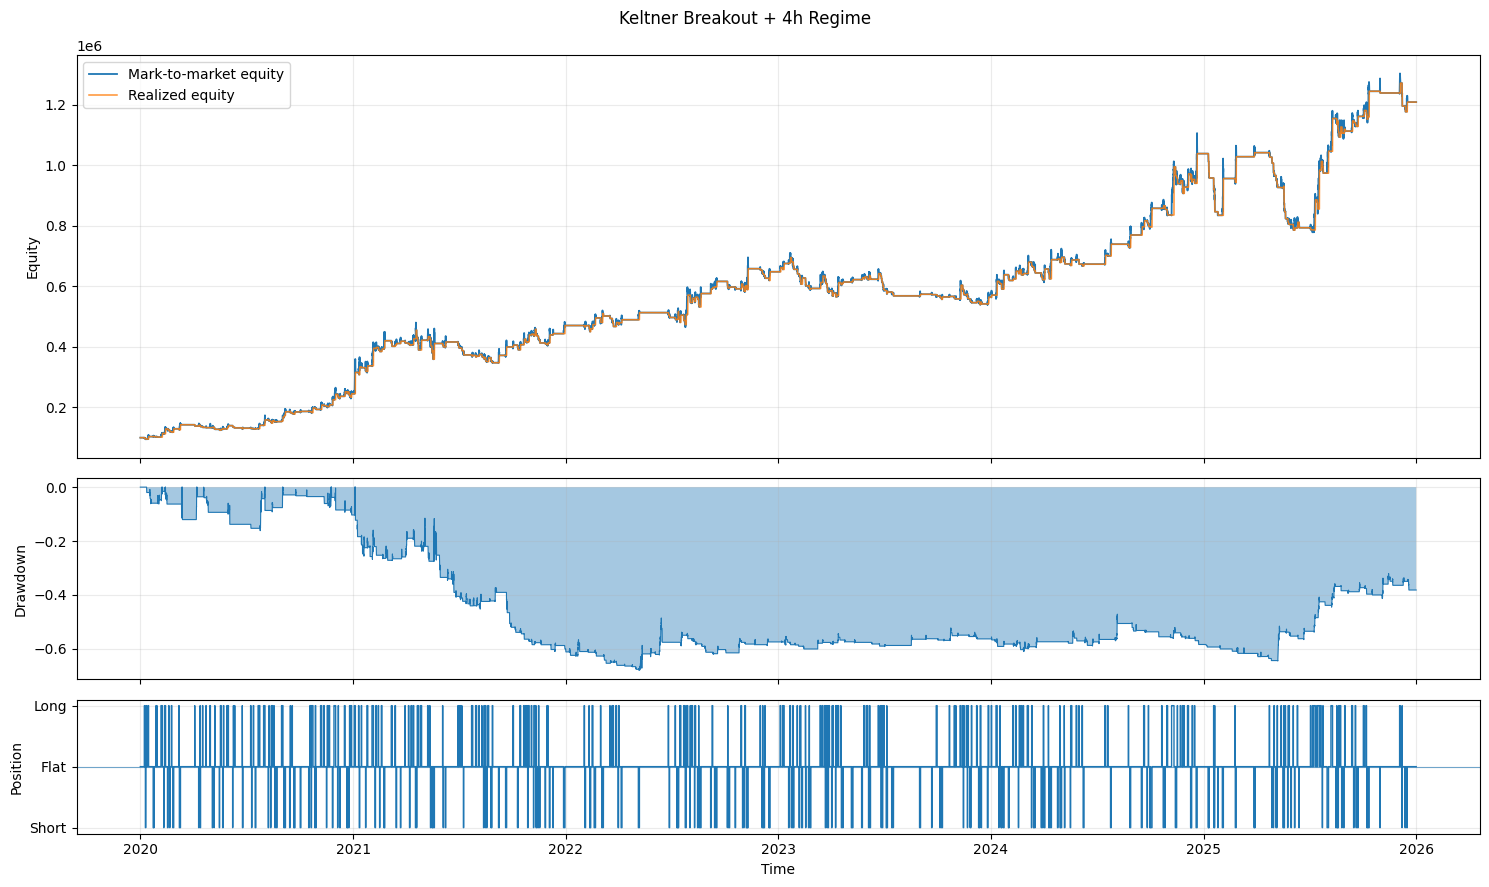

In [223]:
fig, axes = plot_equity_and_drawdown(
    breakout_4h_execution,
    breakout_4h_report,
    title="Keltner Breakout + 4h Regime",
)

plt.show()

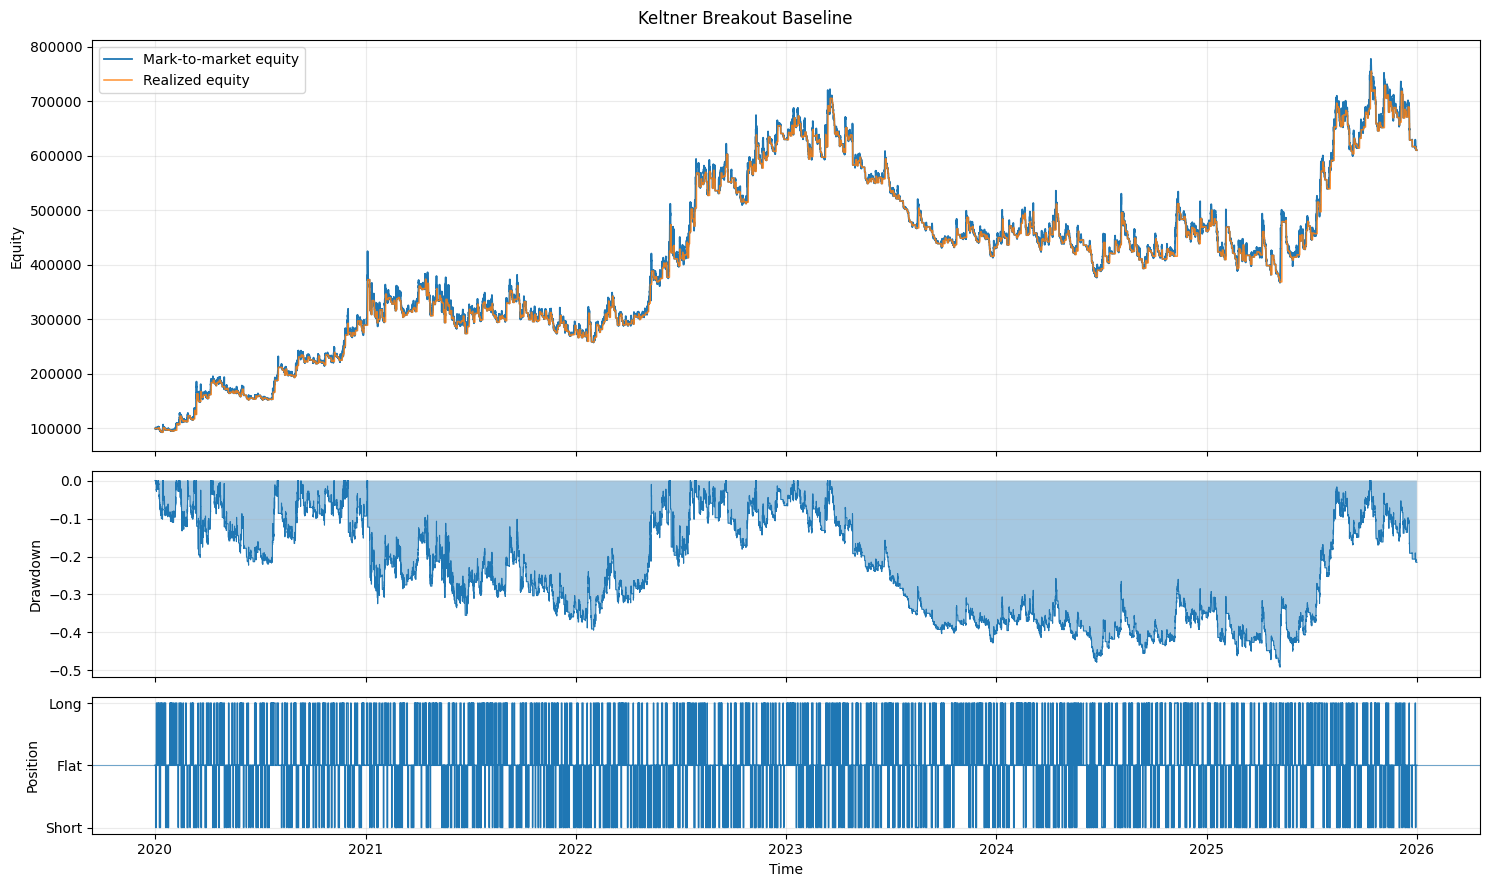

In [224]:
fig, axes = plot_equity_and_drawdown(
    breakout_baseline_execution,
    breakout_baseline_report,
    title="Keltner Breakout Baseline",
)

plt.show()

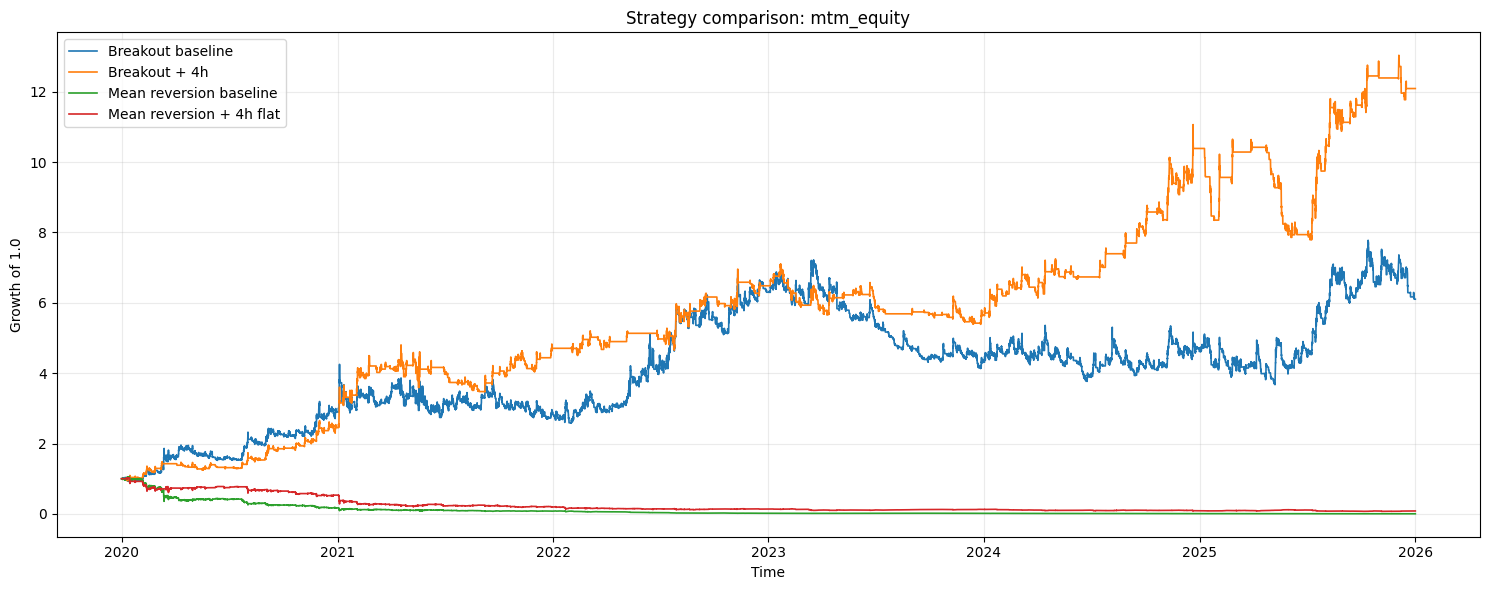

In [225]:
fig, ax = plot_strategy_equity_comparison(
    {
        "Breakout baseline": (
            breakout_baseline_execution
        ),
        "Breakout + 4h": (
            breakout_4h_execution
        ),
        "Mean reversion baseline": (
            mean_reversion_baseline_execution
        ),
        "Mean reversion + 4h flat": (
            mean_reversion_4h_flat_execution
        ),
    }
)

plt.show()

In [226]:
trade_cfg = VisualizationConfig(
    pre_trade_bars=40,
    post_trade_bars=40,

    regime_column=(
        "imom_imacd_4h_confirmed_state"
    ),

    show_keltner=True,
    show_regime_background=True,
    show_mfe_mae=True,
)

In [228]:
breakout_4h_execution

ExecutionResult(strategy_id='keltner_breakout_1h_ema20_atr20_m2_hlc3_rma_current_basis_cross__rf_breakout_4h_directional_7c15537bc4', execution_timeframe='1h', config=ExecutionConfig(initial_capital=100000.0, fee_bps=4.0, slippage_bps=1.0, position_sizing='fraction_of_equity', position_fraction=1.0, leverage=1.0, fixed_notional=10000.0, min_notional=0.0, execution_delay_bars=1, allow_reversal=True, allow_same_bar_reentry=False, entry_conflict_policy='skip', close_position_at_end=True), bars=                                          bar_start     open     high  \
bar_end                                                                 
2020-01-01 01:00:00+00:00 2020-01-01 00:00:00+00:00   129.16   129.19   
2020-01-01 02:00:00+00:00 2020-01-01 01:00:00+00:00   128.87   130.65   
2020-01-01 03:00:00+00:00 2020-01-01 02:00:00+00:00   130.63   130.98   
2020-01-01 04:00:00+00:00 2020-01-01 03:00:00+00:00   130.85   130.89   
2020-01-01 05:00:00+00:00 2020-01-01 04:00:00+00:00   130.21   130

In [231]:
extreme_trades = get_extreme_trade_ids(
    breakout_4h_execution,
    n=5,
)

print(extreme_trades)

{'best': [383, 437, 406, 442, 434], 'worst': [465, 404, 401, 421, 466], 'highest_mfe': [90, 126, 406, 46, 96], 'lowest_mae': [125, 122, 12, 462, 118]}


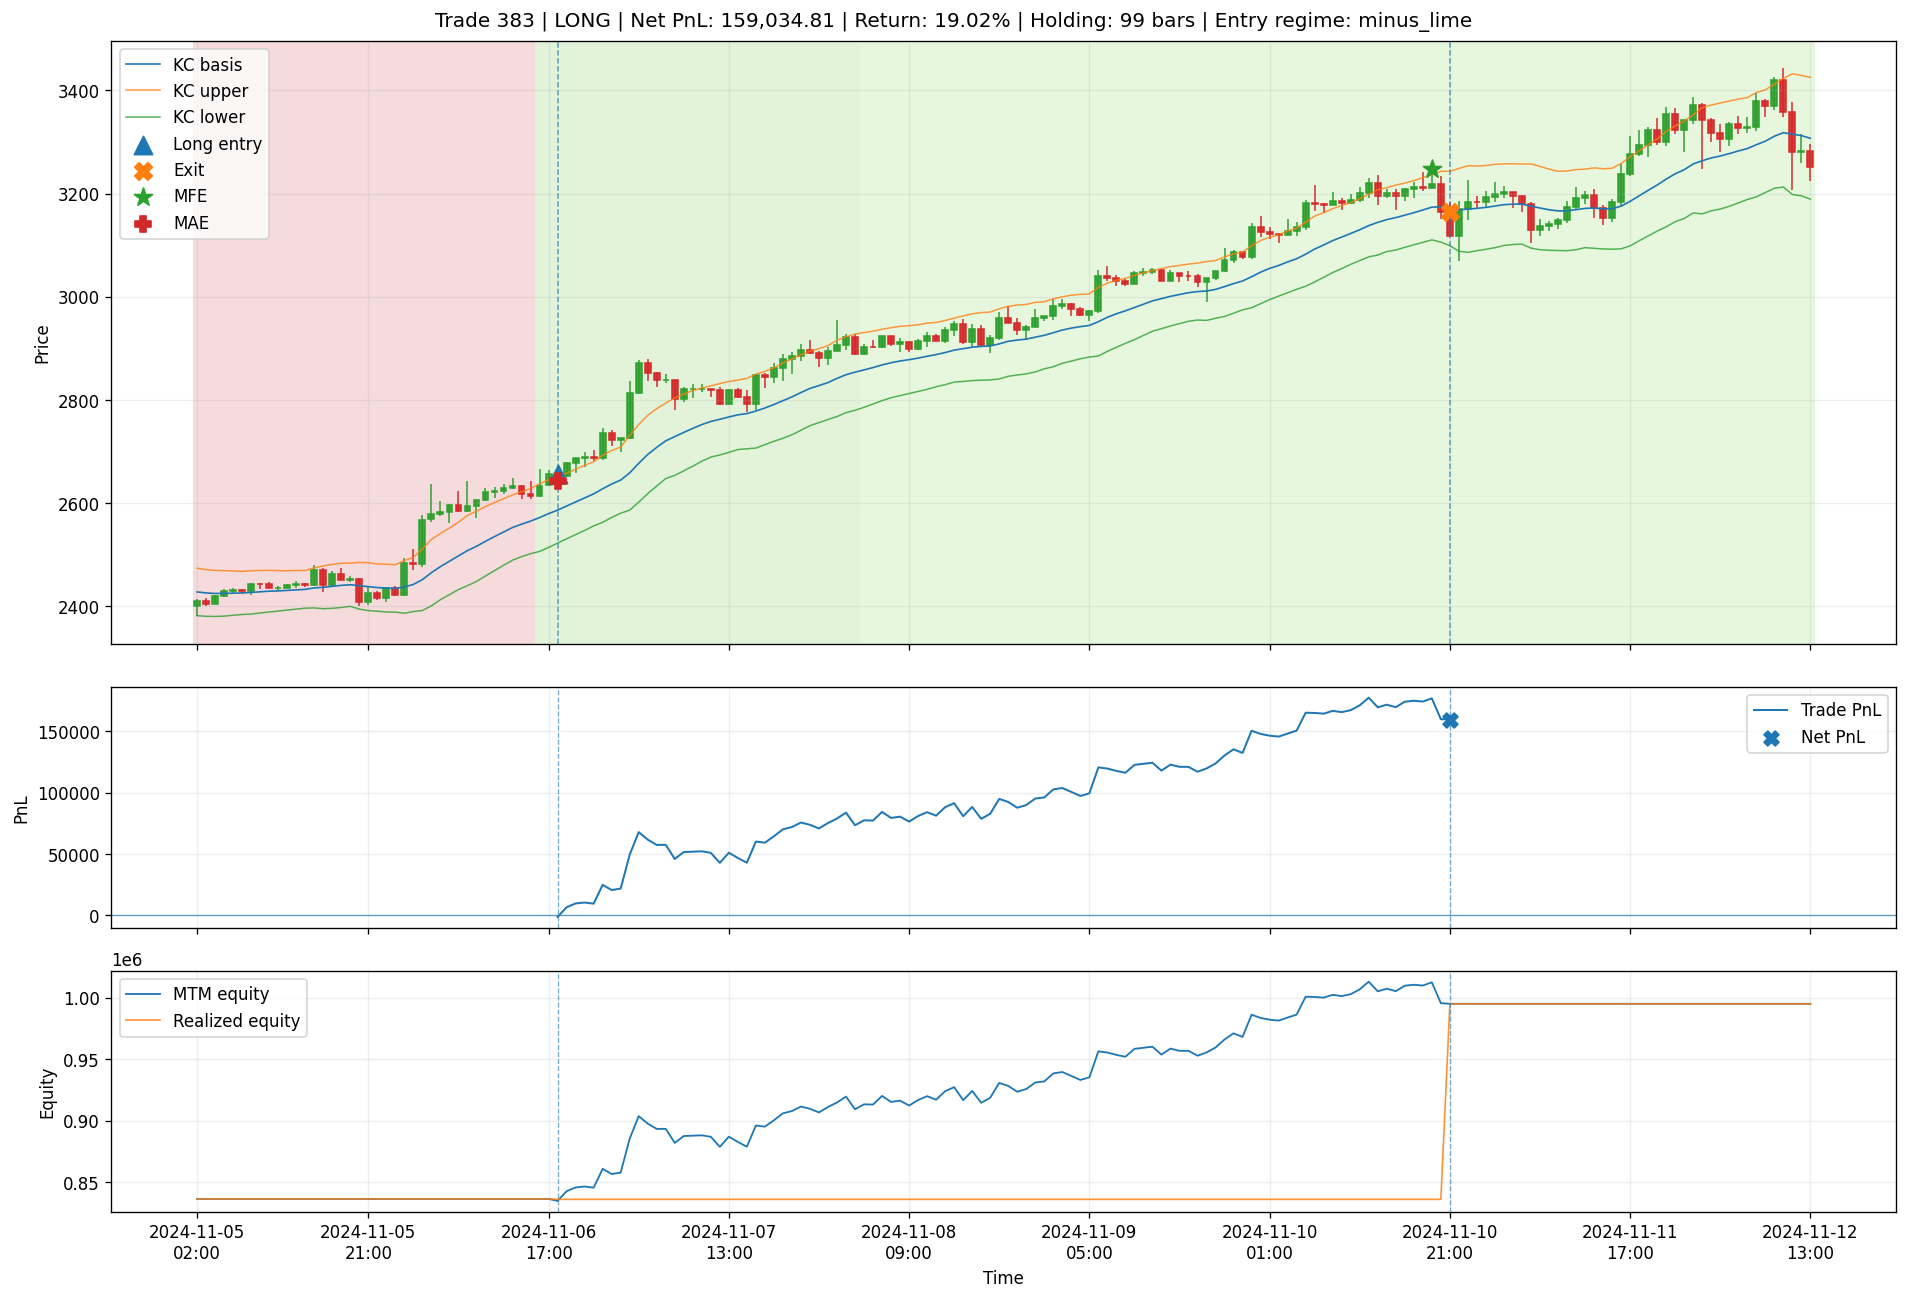

In [233]:
fig, axes = plot_trade(
    breakout_4h_execution,
    trade_id=extreme_trades["best"][0],
    cfg=trade_cfg,
)

plt.show()

In [237]:
breakout_4h_execution

ExecutionResult(strategy_id='keltner_breakout_1h_ema20_atr20_m2_hlc3_rma_current_basis_cross__rf_breakout_4h_directional_7c15537bc4', execution_timeframe='1h', config=ExecutionConfig(initial_capital=100000.0, fee_bps=4.0, slippage_bps=1.0, position_sizing='fraction_of_equity', position_fraction=1.0, leverage=1.0, fixed_notional=10000.0, min_notional=0.0, execution_delay_bars=1, allow_reversal=True, allow_same_bar_reentry=False, entry_conflict_policy='skip', close_position_at_end=True), bars=                                          bar_start     open     high  \
bar_end                                                                 
2020-01-01 01:00:00+00:00 2020-01-01 00:00:00+00:00   129.16   129.19   
2020-01-01 02:00:00+00:00 2020-01-01 01:00:00+00:00   128.87   130.65   
2020-01-01 03:00:00+00:00 2020-01-01 02:00:00+00:00   130.63   130.98   
2020-01-01 04:00:00+00:00 2020-01-01 03:00:00+00:00   130.85   130.89   
2020-01-01 05:00:00+00:00 2020-01-01 04:00:00+00:00   130.21   130

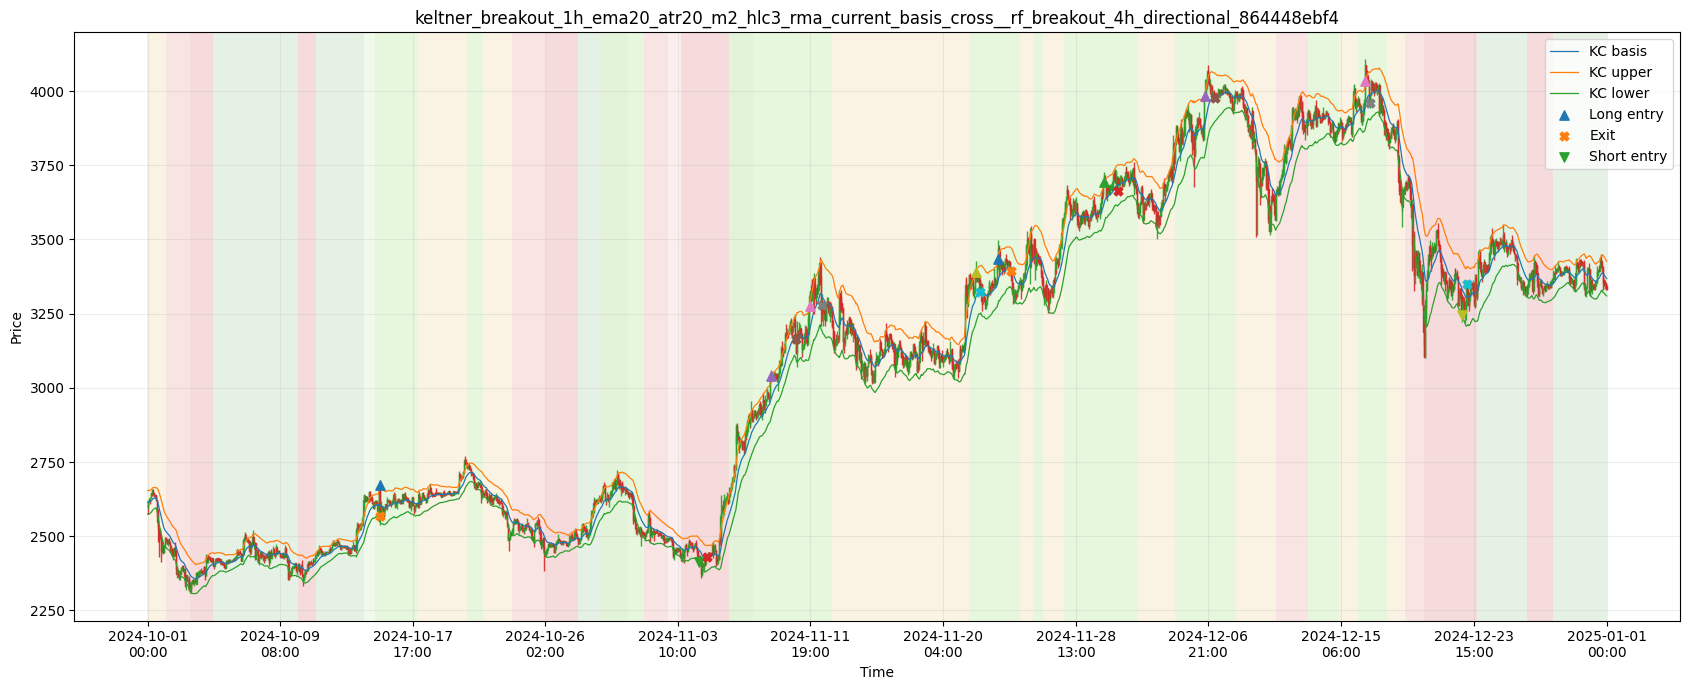

In [299]:
fig, ax = plot_strategy_trades_on_price(
    breakout_4h_execution,

    start="2024-10-01",
    end="2025-01-01",

    regime_column=(
        "imom_imacd_4h_confirmed_state"
    ),
)

plt.show()